### Breast Cancer Detection Using `EfficientNetV2`, `MobileNetV3`, and Modified `AlexNet`

This notebook presents the model training workflow for **BreastGuard**, an mHealth-based breast cancer detection system designed to support early screening in resource-constrained healthcare environments. The study focuses on binary classification of breast histopathology images into **benign** and **malignant** classes using three convolutional neural network architectures: **EfficientNetV2**, **MobileNetV3**, and a **modified AlexNet**.

The experiment uses two publicly available breast cancer image datasets from Kaggle:

> **Breast Cancer Dataset**  
> https://www.kaggle.com/datasets/anaselmasry/breast-cancer-dataset  
> https://www.kaggle.com/datasets/djaidwalid/breast-cancer-dataset/data

The two datasets are merged into one unified dataset to increase data diversity and improve model generalization. The merged dataset contains breast cancer histopathology images organized into two classes: `breast_benign` and `breast_malignant`. Therefore, the task is treated as a **binary image classification problem**, where each input image is classified as either benign or malignant.

The workflow implemented in this notebook includes:

- Loading and merging the two breast cancer datasets
- Organizing images into benign and malignant classes
- Image preprocessing and augmentation
- Dataset splitting into training, validation, and testing sets
- Training EfficientNetV2, MobileNetV3, and modified AlexNet models
- Evaluating model performance using accuracy, precision, recall, F1-score, confusion matrix, and confidence intervals
- Assessing computational efficiency using inference time, model size, memory usage, FLOPs, and MACs
- Applying Grad-CAM explainability to interpret model predictions
- Selecting the best-performing model for integration into the BreastGuard mobile application

The three architectures investigated in this notebook are:

- **EfficientNetV2**, a high-capacity CNN designed using compound scaling for strong image classification performance.
- **MobileNetV3**, a lightweight CNN suitable for mobile and resource-constrained deployment.
- **Modified AlexNet**, a customized classical CNN adapted for binary breast cancer image classification.

This notebook supports the development of **BreastGuard** by identifying an accurate, efficient, and explainable deep learning model for breast cancer detection. The selected model will later be deployed through a **FastAPI backend** and integrated into the BreastGuard mobile application for AI-assisted screening support.

### Citation

> AAbo, A. (2021). *Breast Cancer Dataset*. Kaggle.  
> https://www.kaggle.com/datasets/anaselmasry/breast-cancer-dataset  
>
> Walid, D. (2026). *Breast Cancer Dataset*. Kaggle.  
> https://www.kaggle.com/datasets/djaidwalid/breast-cancer-dataset/data


In this section, we import all the required libraries that will be used throughout the notebook.

In [ ]:
import torch
import random
import os
import time
import math
import json
from pigmenta import PALETTES
import shutil
from pathlib import Path

import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import matplotlib.patches as patches
from shutil import copyfile
from torch.nn import functional as F
from PIL import Image
from torchvision import datasets, transforms
from torch.utils import data
from PIL import Image
from helperfns.tables import tabulate_data
from helperfns.visualization import plot_complicated_confusion_matrix
from helperfns.utils import hms_string

from helperfns import visualization
from torchvision import models
from ptflops import get_model_complexity_info
import warnings

warnings.filterwarnings("ignore")
print("torch: ", torch.__version__)
print("numpy: ", np.__version__)
print("pandas: ", pd.__version__)

torch:  2.9.0+cu126
numpy:  1.26.4
pandas:  2.3.3


### Seed

A fixed random seed (`SEED`) is defined to ensure reproducibility throughout the experiment. This helps maintain consistency in random operations such as dataset splitting, model weight initialization, data shuffling, and training behavior. Using a fixed seed allows the experiments to be repeated under similar conditions and makes the model comparison more reliable.

In [2]:
SEED = 7

random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True

### Device

In this section, a `device` variable is created to automatically detect and use the available computing hardware. If a CUDA-enabled GPU is available, the model training and inference processes will run on the GPU; otherwise, the CPU will be used.

For this experiment, training will be performed on a laptop equipped with an **NVIDIA RTX 3000 Ada Generation Laptop GPU**. The device details are summarized below.

| Component | Specification |
|---|---|
| GPU | NVIDIA RTX 3000 Ada Generation Laptop GPU |
| Driver Version | 32.0.15.9186 |
| Driver Date | 2026/01/20 |
| DirectX Version | 12 (FL 12.2) |
| Physical Location | PCI bus 1, device 0, function 0 |
| Dedicated GPU Memory | 8.0 GB |
| Shared GPU Memory | 15.8 GB |
| Total GPU Memory | 23.8 GB |

Using the GPU helps accelerate deep learning operations such as forward propagation, backpropagation, and batch-wise image processing, making model training more efficient.

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

### Dataset

The datasets used in this project are sourced from Kaggle and focus on **breast cancer histopathology image classification**. This study uses two publicly available breast cancer datasets, which will be merged into one unified dataset for training, validation, and testing.

> **Breast Cancer Dataset**  
> https://www.kaggle.com/datasets/anaselmasry/breast-cancer-dataset  
> https://www.kaggle.com/datasets/djaidwalid/breast-cancer-dataset/data

The first dataset, provided by **AAbo (2021)**, contains cleaned breast cancer histopathology images derived from the BreaKHis dataset. It includes two main classes: **benign** and **malignant**. The second dataset, provided by **Walid (2026)**, follows a predefined `train` and `test` directory structure, with images organized into `breast_benign` and `breast_malignant` folders.

For this project, the two datasets are merged into a single dataset to increase the number of training samples and improve model generalization. The merged dataset is suitable for a **binary image classification** task, where each input image is classified as either:

- **benign**: non-cancerous breast tissue
- **malignant**: cancerous breast tissue

Breast cancer detection is important because early and accurate screening can support timely diagnosis and improve clinical decision-making, especially in resource-constrained healthcare environments where access to specialists and diagnostic infrastructure may be limited. Automated image-based classification can assist healthcare workers by providing faster and more consistent decision-support for breast cancer screening.

Since this project is implemented using **PyTorch**, the folder-based structure of the datasets makes them suitable for loading with PyTorch utilities such as `torchvision.datasets.ImageFolder`. In this setup, each class folder is automatically treated as a separate class label, while image preprocessing and augmentation are handled using `torchvision.transforms`.

To ensure reproducibility and efficient data access, the datasets can be downloaded programmatically using the **Kaggle API**, enabling seamless integration into the PyTorch notebook workflow and simplifying dataset management.

This dataset supports:

- **Binary classification of breast cancer histopathology images**
- **Deep learning-based benign and malignant tissue detection using PyTorch**
- Comparative evaluation of `EfficientNetV2`, `MobileNetV3`, and modified `AlexNet`
- Explainable AI analysis using Grad-CAM
- Development of the **BreastGuard** mHealth application for AI-assisted breast cancer screening support

### Citation

> AAbo, A. (2021). *Breast Cancer Dataset*. Kaggle.  
> https://www.kaggle.com/datasets/anaselmasry/breast-cancer-dataset  
>
> Walid, D. (2026). *Breast Cancer Dataset*. Kaggle.  
> https://www.kaggle.com/datasets/djaidwalid/breast-cancer-dataset/data


In [4]:
with open("C:\\Users\\crisp\\Downloads\\kaggle.json", 'r') as reader:
  keys = json.loads(reader.read())
  os.environ['KAGGLE_USERNAME'] = keys['username']
  os.environ['KAGGLE_KEY'] = keys['key']

if not os.path.exists('BreaKHis_Total_dataset'): 
    !kaggle datasets download anaselmasry/breast-cancer-dataset --unzip -q
else:
    print("The dataset was already downloaded 'anaselmasry/breast-cancer-dataset' before...")

if not os.path.exists('Breast Cancer'): 
    !kaggle datasets download djaidwalid/breast-cancer-dataset --unzip -q
else:
    print("The dataset was already downloaded 'djaidwalid/breast-cancer-dataset' before...")

The dataset was already downloaded 'anaselmasry/breast-cancer-dataset' before...
The dataset was already downloaded 'djaidwalid/breast-cancer-dataset' before...


### Merging the Datasets

In the following code cell, the two breast cancer datasets are merged into one unified dataset. The images from both datasets are organized into two class folders: `benign` and `malignant`.

This merging step is performed to increase the number of available samples, improve data diversity, and support better model generalization during training. After merging, the unified dataset will be used for dataset splitting, preprocessing, augmentation, model training, validation, and testing.

In [5]:
dataset_dir = Path("Breast Cancer")
merged_dir = Path("Merged Dataset")
class_mapping = {
    "breast_benign": "benign",
    "breast_malignant": "malignant"
}
copy_files = True
if os.path.exists(merged_dir):
    print("The datasets were already merged!")
else:
    print("copying images..." if copy_files else "moving images...")
    subsets = ["train", "test"]
    for new_class_name in class_mapping.values():
        (merged_dir / new_class_name).mkdir(parents=True, exist_ok=True)
        
    for subset in subsets:
        subset_dir = dataset_dir / subset
        for old_class_name, new_class_name in class_mapping.items():
            source_class_dir = subset_dir / old_class_name
            target_class_dir = merged_dir / new_class_name
            if not source_class_dir.exists():
                print(f"Skipping missing folder: {source_class_dir}")
                continue
            for image_path in source_class_dir.iterdir():
                if image_path.is_file():
                    new_filename = f"{subset}_{image_path.name}"
                    target_path = target_class_dir / new_filename
                    if copy_files:
                        shutil.copy2(str(image_path), str(target_path))
                    else:
                        shutil.move(str(image_path), str(target_path))

    new_dataset_dir = Path("BreaKHis_Total_dataset")
    for class_name in class_mapping.values():
        source_class_dir = new_dataset_dir / class_name
        target_class_dir = merged_dir / class_name
        target_class_dir.mkdir(parents=True, exist_ok=True)
        if not source_class_dir.exists():
            print(f"Skipping missing folder: {source_class_dir}")
            continue
        for image_path in source_class_dir.iterdir():
            if image_path.is_file():
                new_filename = f"extra_{image_path.name}"
                target_path = target_class_dir / new_filename
                if copy_files:
                    shutil.copy2(str(image_path), str(target_path))
                else:
                    shutil.move(str(image_path), str(target_path))
    
    print("Dataset merging completed successfully.")

The datasets were already merged!


### Class Distribution

After merging the two breast cancer datasets, the unified dataset will be organized into two class folders: `benign` and `malignant`.

In the next code cell, the number of samples in each class will be counted. This step helps us understand the **class distribution** of the merged dataset and identify any potential class imbalance that may affect model training.

Understanding the class distribution is important because imbalanced datasets can cause a model to perform better on the majority class while performing poorly on the minority class. Therefore, this analysis helps guide later decisions such as data augmentation, class weighting, or balanced sampling during training.

In [6]:
base_dir = merged_dir
samples = dict(
    zip(os.listdir(base_dir), [len(os.listdir(os.path.join(base_dir, i))) for i in os.listdir(base_dir)])
)
samples

{'benign': 7479, 'malignant': 10304}

### Visualizing Class Distribution

In the following code cell, the class distribution of the merged breast cancer dataset will be visualized using a **pie chart**. The dataset contains two class folders: `benign` and `malignant`.

This visualization provides a clear view of the proportion of samples in each class and helps identify whether the dataset is balanced or imbalanced. Understanding this distribution is important because class imbalance may affect model training and can influence the model’s ability to correctly classify both benign and malignant breast cancer images.

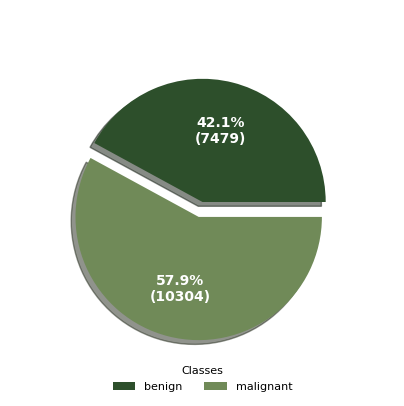

In [7]:
examples = samples
plt.figure(figsize=(5, 5), dpi=100)
def fmt(x, total):
    return '{:.1f}%\n({:.0f})'.format(x, total*x/100)

plt.pie(
    examples.values(), labels=examples.keys(), explode= [0. if i%2 == 0 else .1 for i in range(len(samples))],
    pctdistance=0.6, shadow=True, autopct=lambda x: fmt(x, sum(examples.values())),
    textprops={'color': 'white', 'fontsize': 10, 'weight': 'bold'},
    radius=.8, colors=PALETTES.nature,
)
plt.legend(
    fontsize=8, loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    title="Classes", ncol=3, frameon=False, title_fontsize=8
)
plt.show()

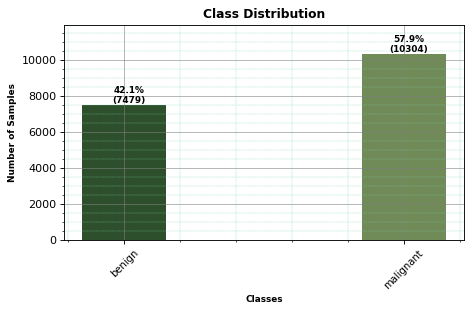

In [8]:
labels = list(examples.keys())
values = list(examples.values())

def fmt_bar(x, total):
    return '{:.1f}%\n({:.0f})'.format(x/total *100, x)

plt.figure(figsize=(6, 4), dpi=80)
plt.ylim(0, max(values) * 1.16)
bars = plt.bar(labels, values, width=.3, color=PALETTES.nature)
for index, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 1.8,
        height,
        fmt_bar(values[index], sum(values)),
        ha='center',
        va='bottom',
        fontsize=8,
        weight='bold'
    )

plt.xlabel('Classes', fontsize=8, weight='bold')
plt.xticks(rotation=45, fontsize=9)
plt.ylabel('Number of Samples', fontsize=8, weight='bold')
plt.title('Class Distribution', fontsize=11, weight='bold')
plt.minorticks_on()
plt.grid(which='major', color='gray', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='#7ED4AD', linestyle='--', linewidth=0.3)
plt.tight_layout()
plt.show()

### Class Weight Computation

Since the merged breast cancer dataset is imbalanced, class weights are computed and incorporated into the loss function. This helps the model place greater emphasis on the underrepresented class by assigning a higher penalty to misclassification errors from minority-class samples.

The class weight for each class is computed as:

$$
w_i = \frac{N}{K \cdot n_i}
$$

Where:

- $w_i$ is the weight assigned to class $i$
- $N = \sum_{i=1}^{K} n_i$ is the total number of samples in the dataset
- $K$ is the total number of classes
- $n_i$ is the number of samples in class $i$

In this project, the two classes are:

- `benign`
- `malignant`

An alternative normalized form can also be expressed as:

$$
w_i = \frac{\frac{1}{n_i}}{\sum_{j=1}^{K} \frac{1}{n_j}} \times K
$$

Both formulations assign higher weights to classes with fewer samples and lower weights to classes with more samples. These weights are later passed to the loss function during model training to reduce bias toward the majority class and improve classification performance on both benign and malignant breast cancer images.

In [9]:
def get_class_weights(values):
    values = torch.tensor(values, dtype=torch.float32)
    total = values.sum()
    weights = total / (len(values) * values)
    return weights
class_weights = get_class_weights(list(samples.values()))
class_weights

tensor([1.1889, 0.8629])

In the following code cell we are going to plot the class-weights.

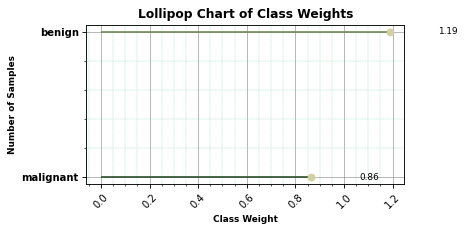

In [10]:
sorted_indices = torch.argsort(class_weights)
sorted_weights = class_weights[sorted_indices]
sorted_names = [list(samples.keys())[i] for i in sorted_indices]

plt.figure(figsize=(6, 3), dpi=80)
plt.hlines(y=sorted_names, xmin=0, xmax=sorted_weights.numpy(), color=PALETTES.nature)
plt.plot(sorted_weights.numpy(), sorted_names, 'o', color=PALETTES.nature[20])

for x, y in zip(sorted_weights, sorted_names):
    plt.text(x + 0.2, y, f"{x:.2f}", va='center', fontsize=8)


plt.xlabel("Class Weight", fontsize=8, weight='bold')
plt.yticks(fontsize=9, weight="bold")
plt.xticks(rotation=45, fontsize=9)
plt.ylabel('Number of Samples', fontsize=8, weight='bold')
plt.title("Lollipop Chart of Class Weights", fontsize=11, weight='bold')
plt.minorticks_on()
plt.grid(which='major', color='gray', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='#7ED4AD', linestyle='--', linewidth=0.3)
plt.tight_layout()
plt.show()

### Channel Means and Standard Deviations

In the next code cell, the **mean** and **standard deviation** for each RGB color channel are computed using only the **training dataset**. These statistics are used to normalize the input images before they are passed into the deep learning models.

Normalization helps stabilize training by ensuring that pixel values are placed on a consistent scale. This can improve convergence, reduce training instability, and make the learning process more efficient.

The computed statistics include:

- Mean for the red, green, and blue channels
- Standard deviation for the red, green, and blue channels

To avoid recomputing these values every time the notebook is executed, the calculated statistics will be cached in a `stats.txt` file. If the file already exists, the saved values will be loaded directly; otherwise, the statistics will be computed and stored for future use.

In [11]:
train_data = datasets.ImageFolder(
    root=base_dir,
    transform= transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
      ])
    )
means = torch.zeros(3)
stds = torch.zeros(3)

stats_path = "stats.txt"

if not os.path.exists(stats_path):
    print("Computing statistics....")
    for img, label in train_data:
      means += torch.mean(img, dim = (1,2))
      stds += torch.std(img, dim = (1,2))
    means /= len(train_data)
    stds /= len(train_data)
    with open(stats_path, 'w') as writer:
        writer.write(f"means {" ".join(str(i.item()) for i in means)}\n")
        writer.write(f"stds {" ".join(str(i.item()) for i in stds)}")
    print(f"\nCached statistics at '{stats_path}'....")
else:
    print("Loading statistics from cache...")
    with open(stats_path, encoding="utf8") as stats:
        for line in stats:
            records = line.split();
            word = records[0]
            if word == "means":
                means = torch.from_numpy(np.asarray(records[1: ], dtype=np.float32))
            else:
                stds = torch.from_numpy(np.asarray(records[1: ], dtype=np.float32))
    
print(f'Calculated means: {means}')
print(f'Calculated stds: {stds}')

Loading statistics from cache...
Calculated means: tensor([0.7659, 0.6125, 0.7472])
Calculated stds: tensor([0.1083, 0.1436, 0.0901])


### Image Preprocessing, Normalization, and Augmentation

A single image preprocessing pipeline is used for all three models: `EfficientNetV2`, `MobileNetV3`, and modified `AlexNet`. This ensures that all models are trained and evaluated under the same data conditions, making the comparison fair and consistent.

All images are resized to **224 × 224 pixels** to match the input size required by pretrained CNN architectures. The images are also converted to tensors and normalized using the computed channel-wise mean and standard deviation from the training dataset.

Data augmentation is applied only to the training set to improve generalization and reduce overfitting. The validation and test sets are not augmented, ensuring fair and unbiased model evaluation.

| Dataset Split | Transformations Applied | Purpose |
|---|---|---|
| Training | Resize to 224 × 224, random rotation of 5°, random horizontal flip, random crop with padding of 10, convert to tensor, normalize using computed mean and standard deviation | Improves generalization and reduces overfitting |
| Validation | Resize to 224 × 224, convert to tensor, normalize using computed mean and standard deviation | Ensures consistent validation without random augmentation |
| Testing | Resize to 224 × 224, convert to tensor, normalize using computed mean and standard deviation | Ensures unbiased final model evaluation |

Using one shared data pipeline ensures that any performance differences observed between `EfficientNetV2`, `MobileNetV3`, and modified `AlexNet` are due to model architecture rather than differences in preprocessing or augmentation.

In [12]:
image_transforms = {
    "train": transforms.Compose([
              transforms.Resize((224, 224)),
              transforms.RandomRotation(5),
              transforms.RandomHorizontalFlip(.5),
              transforms.RandomCrop(224, padding=2),
              transforms.ToTensor(),
              transforms.Normalize(mean=means, std=stds, inplace=False)
          ]),
    "valid": transforms.Compose([
          transforms.Resize((224, 224)),
          transforms.ToTensor(),
          transforms.Normalize(mean = means,
                            std = stds)
        ]),
    "test": transforms.Compose([
          transforms.Resize((224, 224)),
          transforms.ToTensor(),
          transforms.Normalize(mean = means, std = stds)
    ])
}

### Dataset Loading with ImageFolder

In the following code cell, the breast cancer image datasets are loaded using the `ImageFolder` class from PyTorch. This utility automatically reads the folder-based dataset structure and maps each class folder to a numerical class label.

In this project, the merged dataset contains two class folders:

- `benign`
- `malignant`

`ImageFolder` assigns each image to its corresponding class based on the folder in which it is stored. This simplifies dataset preparation and makes it easier to create training, validation, and testing datasets for model development and evaluation.

In [13]:
dataset = datasets.ImageFolder(base_dir, transform = image_transforms['train'])
class_names = dataset.classes
class_names

['benign', 'malignant']

## Data Splitting

The merged breast cancer dataset is divided into three subsets: **training**, **validation**, and **testing**. First, **20%** of the dataset is reserved as the independent test set. The remaining **80%** is then split into **80% training** and **20% validation**, resulting in an approximate final split of **64% training**, **16% validation**, and **20% testing**.

| Splitting Stage | Proportion | Description |
|---|---:|---|
| Initial test split | 20% | Reserved for final model evaluation |
| Remaining data | 80% | Used to create the training and validation sets |
| Training from remaining data | 80% of remaining 80% | Used for model learning |
| Validation from remaining data | 20% of remaining 80% | Used to monitor training performance |

The final dataset distribution is summarized below.

| Dataset Split | Final Proportion | Purpose |
|---|---:|---|
| Training | 64% | Used to learn model parameters |
| Validation | 16% | Used to monitor performance during training and guide model selection |
| Testing | 20% | Kept separate for final, unbiased model evaluation |

This splitting strategy ensures that the models are trained, validated, and tested on separate subsets, supporting fair comparison between `EfficientNetV2`, `MobileNetV3`, and modified `AlexNet`.

In [14]:
VALID_RATIO = 0.2
TEST_RATIO = 0.2

# Split into train + test
n_test_examples = int(len(dataset) * TEST_RATIO)
n_train_examples = len(dataset) - n_test_examples

train_data, test_data = data.random_split(dataset,
                                          [n_train_examples, n_test_examples])
n_valid_examples = int(len(train_data) * VALID_RATIO)
n_train_examples = len(train_data) - n_valid_examples
train_data, valid_data = data.random_split(train_data,
                                           [n_train_examples, n_valid_examples])

### Visualizing Dataset Split Distribution

In the following code cell, a **pie chart** will be used to visualize the number of examples in each dataset subset: **training**, **validation**, and **testing**.

This visualization provides a clear summary of how the merged breast cancer dataset is distributed after splitting. It also helps confirm that the final data split follows the intended proportions of approximately **64% training**, **16% validation**, and **20% testing**.

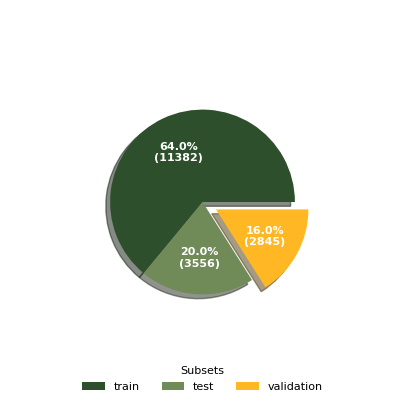

In [15]:
plt.figure(figsize=(5, 5), dpi=100)
plt.pie(
    [len(train_data), len(test_data), len(valid_data)], explode= [.0, .0, .1],
    labels=['train', 'test', 'validation'],
    pctdistance=0.6, shadow=True, autopct=lambda x: fmt(x, sum([len(train_data), len(test_data), len(valid_data)])),
    textprops={'color': 'white', 'fontsize': 8, 'weight': 'bold'},
    radius=.6, colors=PALETTES.nature
)
plt.legend(
    fontsize=8,  loc="upper center",
    bbox_to_anchor=(0.5, 0.1),
    title="Subsets", ncol=3, frameon=False, title_fontsize=8
)
plt.show()

In the following code cell, a **bar chart** will be used to visualize the distribution of labels in the merged breast cancer dataset.

This chart shows the number of images available for each class: `benign` and `malignant`. Visualizing the label distribution helps identify class imbalance and provides a clearer understanding of how many examples are available for each category before model training.

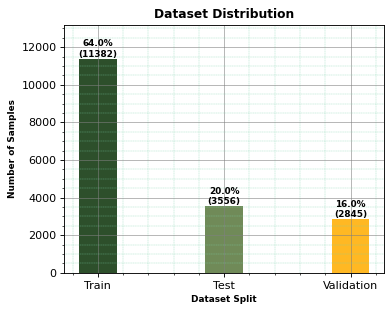

In [16]:
labels = ['Train', 'Test', 'Validation']
values = [len(train_data), len(test_data), len(valid_data)]

def fmt_bar(x, total):
    return '{:.1f}%\n({:.0f})'.format(x/total *100, x)
    
plt.figure(figsize=(5, 4), dpi=80 )
plt.ylim(0, max(values) * 1.16)
bars = plt.bar(labels, values, width=.3, color=PALETTES.nature)
for index, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        fmt_bar(values[index], sum(values)),
        ha='center',
        va='bottom',
        fontsize=8,
        weight='bold'
    )

plt.xlabel('Dataset Split', fontsize=8, weight='bold')
plt.ylabel('Number of Samples', fontsize=8, weight='bold')
plt.title('Dataset Distribution', fontsize=11, weight='bold')
plt.minorticks_on()
plt.grid(which='major', color='gray', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='#7ED4AD', linestyle='--', linewidth=0.3)
plt.tight_layout()
plt.show()

### Data Loaders

In this step, data loaders are constructed for the training, validation, and test datasets. These loaders enable efficient **batch-wise data processing**, which is important for scalable model training and evaluation.

A **batch size of 128** is used to improve training throughput while still considering available GPU memory. This allows multiple images to be processed in each forward and backward pass, making training more efficient.

The data loaders are configured as follows:

| Data Loader | Batch Size | Shuffle | Purpose |
|---|---:|---|---|
| Training loader | 128 | Enabled | Supports randomized batch sampling during training to improve generalization |
| Validation loader | 128 | Disabled | Ensures consistent validation during model selection |
| Test loader | 128 | Disabled | Ensures stable and reproducible final evaluation |

This configuration supports efficient model training while maintaining reliable and consistent performance assessment across `EfficientNetV2`, `MobileNetV3`, and modified `AlexNet`.

In [17]:
BATCH_SIZE = 128
train_iterator = data.DataLoader(
    train_data, shuffle=True, batch_size= BATCH_SIZE
)
valid_iterator = data.DataLoader(
    valid_data, batch_size= BATCH_SIZE
)
test_iterator = data.DataLoader(
    test_data,  batch_size= BATCH_SIZE
)

### Visualizing Images

In this section, a selection of images from the merged breast cancer dataset is visualized together with their corresponding class labels.

This step provides an initial visual understanding of the dataset and helps confirm that the images are correctly loaded and aligned with their labels. It also allows quick inspection of sample differences between the `benign` and `malignant` classes before model training begins.

In [18]:
def normalize_image(image):
  image_min = image.min()
  image_max = image.max()
  image.clamp_(min = image_min, max = image_max)
  image.add_(-image_min).div_(image_max - image_min + 1e-5)
  return image

Next we are going to define the `plot_images` function which is responsible for plotting images.

In [19]:
def plot_images(images, labels, normalize = True):
  n_images = len(images)
  rows = int(np.sqrt(n_images))
  cols = int(np.sqrt(n_images))
  fig = plt.figure(figsize = (10, 10), dpi=100)
  for i in range(rows*cols):
    ax = fig.add_subplot(rows, cols, i+1)
    image = images[i]
    if normalize:
        image = normalize_image(image)
    ax.imshow(image.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    ax.set_title(class_names[labels[i]], fontsize=10, color='r' if labels[i] != 0 else 'g')
    ax.axis('off')

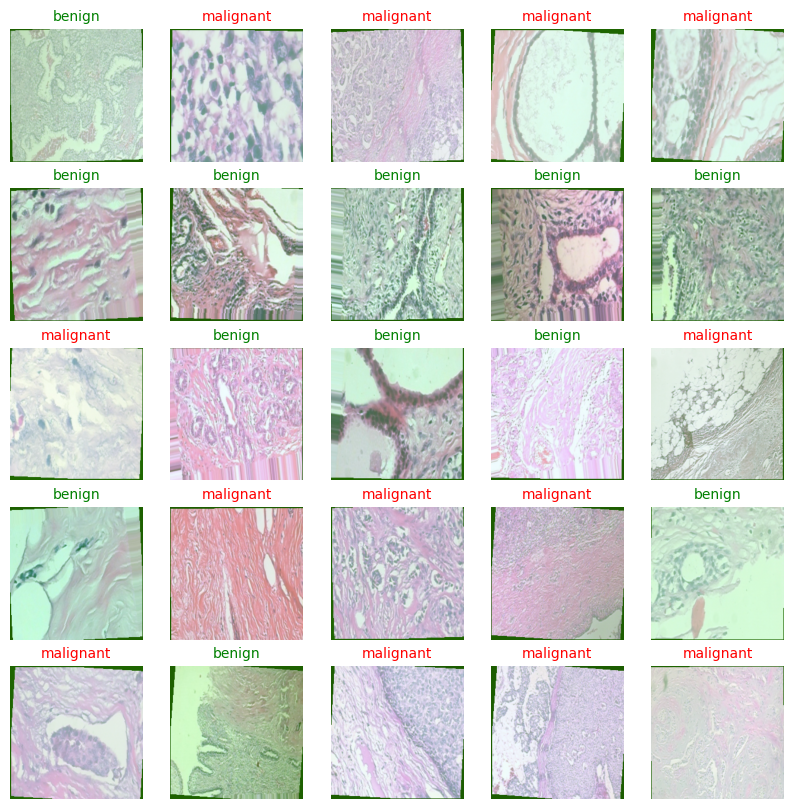

In [20]:
N_IMAGES = 25
labeled_data = next(iter(test_iterator))

images, labels = labeled_data[0][:N_IMAGES], labeled_data[1][:N_IMAGES]
plot_images(images, labels)

#### Model Architectures

In the following code cell, three deep learning models are defined for the **BreastGuard breast cancer image classification** task. This study compares `MobileNetV3`, `EfficientNetV2`, and a modified `AlexNet` for binary classification of breast histopathology images into `benign` and `malignant` classes.

`MobileNetV3` and `EfficientNetV2` are used as transfer learning models and adapted by modifying their final classification layers to match the two output classes. A modified `AlexNet` is also implemented as a classical CNN baseline for comparison.

| Model | Description | Role in This Study |
|---|---|---|
| `MobileNetV3` | Lightweight CNN designed for efficient inference on mobile and resource-constrained devices | Evaluates suitability for BreastGuard mobile deployment |
| `EfficientNetV2` | Modern CNN designed for improved training efficiency, scalability, and strong image classification performance | Evaluates high-performance feature learning and classification accuracy |
| Modified `AlexNet` | Classical CNN adapted for binary breast cancer classification | Provides a baseline for comparison against modern architectures |

These models allow comparison between lightweight, high-capacity, and classical CNN architectures. The evaluation will focus on classification performance, computational efficiency, explainability, and suitability for integration into the **BreastGuard** mHealth application.

In [21]:
mobilenetv3 = models.mobilenet_v3_large(weights = True).to(device)
efficientnetv2 = models.efficientnet_v2_s(weights='IMAGENET1K_V1').to(device)

### Output Dimension

Next, the output dimension of each model is defined to match the breast cancer classification task.

Since this is a **binary classification** problem, the final output layer produces **one prediction score**. This single output score represents the model’s confidence for the positive class, while the final class label is determined using a sigmoid activation and a decision threshold.

In this project, the two classes are:

- `benign`
- `malignant`

| Model | Output Dimension | Final Activation | Task |
|---|---:|---|---|
| `MobileNetV3` | 1 | Sigmoid | Benign vs malignant classification |
| `EfficientNetV2` | 1 | Sigmoid | Benign vs malignant classification |
| Modified `AlexNet` | 1 | Sigmoid | Benign vs malignant classification |

The pretrained models are **not frozen** in this study. Instead, all model parameters are allowed to update during training. This enables the models to fine-tune their learned features on the merged breast cancer dataset and learn breast histopathology-specific visual patterns more effectively.

In [22]:
OUTPUT_DIM = 1 if len(class_names) == 2 else len(class_names)
def freeze_model(model):
  for param in model.parameters():
    param.requires_grad = False

### Reconfiguring Classification Layers

In the following code cell, the final classification layers of `MobileNetV3` and `EfficientNetV2` are reconfigured to match the binary breast cancer classification task.

Since this project classifies breast histopathology images into `benign` and `malignant`, each model is modified to produce **one output score**. This output is later passed through a sigmoid activation function to determine the final predicted class.

The pretrained models are fine-tuned in an **end-to-end** manner, with no layers frozen. This means that all model parameters remain trainable and are updated during training. By allowing the full network to learn from the breast cancer image dataset, the models can adapt their pretrained visual features to capture task-specific histopathology patterns.

This fine-tuning strategy supports improved feature learning and enables a fair comparison between `MobileNetV3` and `EfficientNetV2`.

In [23]:
mobilenetv3.classifier[-1] = nn.Linear(mobilenetv3.classifier[-1].in_features, OUTPUT_DIM).to(device)
efficientnetv2.classifier[-1] = nn.Linear(mobilenetv3.classifier[-1].in_features, OUTPUT_DIM).to(device)

In [24]:
class AlexNet(nn.Module):
  def __init__(self, output_dim):
    super(AlexNet, self).__init__()

    self.features = nn.Sequential(
        nn.Conv2d(3, 64, 3, 2, 1), # in_channels, out_channels, kernel_size, stride, padding
        nn.MaxPool2d(2),
        nn.ReLU(inplace=True),
        nn.Conv2d(64, 192, 3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(inplace=True),
        nn.Conv2d(192, 384, 3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(384, 256, 3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(256, 256, 3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(inplace=True),
        nn.Conv2d(256, 128, 3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(inplace=True),
        nn.Conv2d(128, 64, 3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(inplace=True),
    )

    self.classifier = nn.Sequential(
        nn.Dropout(.5),
        nn.Linear(64 * 3 * 3, 4096),
        nn.ReLU(inplace=True),
        nn.Dropout(.5),
        nn.Linear(4096, 4096),
        nn.ReLU(inplace=True),
        nn.Linear(4096, output_dim),
    )

  def forward(self, x):
    x = self.features(x)
    h = x.view(x.shape[0], -1)
    x = self.classifier(h)
    return x

### Instantiating Modified AlexNet

In the following code cell, the modified `AlexNet` architecture is instantiated for the **BreastGuard breast cancer classification** task.

This step initializes all model parameters and prepares the network for training on the merged breast cancer dataset. The model is adapted for **binary classification** by producing one output score for distinguishing between `benign` and `malignant` breast histopathology images.

In [25]:
alexnet = AlexNet(OUTPUT_DIM).to(device)
alexnet

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU(inplace=True)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): ReLU(inplace=True)
    (13): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): ReLU(inplace=Tru

### Model Complexity Analysis

In this section, model complexity is evaluated by computing the **number of parameters** and estimating the computational cost using **FLOPs** and **MACs**.

| Metric | Description |
|---|---|
| Parameters | Total number of trainable and non-trainable values in the model |
| MACs | Multiply–Accumulate operations required during a forward pass |
| FLOPs | Approximate number of floating-point operations required during inference |

FLOPs are commonly estimated from MACs as:

$$
\text{FLOPs} \approx 2 \times \text{MACs}
$$

This analysis is important for comparing `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` beyond accuracy. It helps assess computational efficiency, inference cost, and suitability for deployment in the **BreastGuard** mHealth application, especially in resource-constrained environments.

Although FLOPs provide a useful estimate of computational complexity, actual runtime may still vary depending on hardware, memory access, and software optimization.

In [26]:
def count_params(model):
  total_params = sum([p.numel() for p in model.parameters()])
  trainable_params = sum([p.numel() for p in model.parameters() if p.requires_grad])
  return f'{total_params:,}', f'{trainable_params:,}', f'{total_params - trainable_params:,}'

def compute_flops(model):
    with torch.cuda.device(0):  
        macs, params = get_model_complexity_info(
            model,
            (3, 224, 224),
            as_strings=True,
            print_per_layer_stat=False,
            verbose=False
        )
    return macs, params

Then we will visualize the model parameters using a table.

In [27]:
tabulate_data(
    ["NAME", "TOTAL PARAMETERS", "TRAINABLE PARAMETERS", "NON-TRAINABLE PARAMETERS", "FLOPs (MACs)", "SHORTENED PARAMS",],
    [
      ['AlexNet', *count_params(alexnet), *compute_flops(alexnet)],
      ['MobileNetV3', *count_params(mobilenetv3), *compute_flops(mobilenetv3)],
      ['EfficientNetV2', *count_params(efficientnetv2), *compute_flops(efficientnetv2)],
    ],
    "MODELS' PARAMETERS"
)

MODELS' PARAMETERS
+----------------+------------------+----------------------+--------------------------+--------------+------------------+
| NAME           | TOTAL PARAMETERS | TRAINABLE PARAMETERS | NON-TRAINABLE PARAMETERS | FLOPs (MACs) | SHORTENED PARAMS |
+----------------+------------------+----------------------+--------------------------+--------------+------------------+
| AlexNet        |       21,769,217 |           21,769,217 |                        0 |    2.13 GMac |          21.77 M |
| MobileNetV3    |        4,203,313 |            4,203,313 |                        0 |  230.04 MMac |            4.2 M |
| EfficientNetV2 |       20,178,769 |           20,178,769 |                        0 |    2.89 GMac |          20.18 M |
+----------------+------------------+----------------------+--------------------------+--------------+------------------+


### Criterion and Optimizer

Next, the **optimizer** and **loss function** are defined for training `MobileNetV3`, `EfficientNetV2`, and the modified `AlexNet`.

The **Adam optimizer** is used because it adaptively updates the learning rate for each model parameter during training. This makes it suitable for fine-tuning pretrained CNN models and training the modified AlexNet architecture.

| Adam Parameter | Default Value | Description |
|---|---:|---|
| Learning rate | 0.001 | Controls the step size during parameter updates |
| Beta 1 | 0.9 | Controls the moving average of the gradient |
| Beta 2 | 0.999 | Controls the moving average of the squared gradient |
| Epsilon | 1e-8 | Prevents division by zero during optimization |
| Weight decay | 0 | Applies L2 regularization when enabled |

Since this is a **binary classification** task, the models produce one output score. Therefore, **BCEWithLogitsLoss** is used as the loss function because it combines sigmoid activation and binary cross-entropy in a numerically stable way.

To address class imbalance, the `pos_weight` argument is used. This increases the penalty for misclassifying the minority positive class. In this project, the `benign` class has fewer samples, so it should receive a higher weight if it is treated as the positive class.

The positive class weight is computed as:

$$
\text{pos\_weight} = \frac{n_{\text{negative}}}{n_{\text{positive}}}
$$

Where:

- $n_{\text{positive}}$ is the number of samples in the positive class
- $n_{\text{negative}}$ is the number of samples in the negative class

This weighting helps reduce bias toward the majority class and encourages the models to learn more balanced decision boundaries between `benign` and `malignant` breast cancer images.

In [28]:
pos_weight = torch.tensor([class_weights.max() /class_weights.min()]).to(device)
print(f"The positive weight is: {pos_weight.detach().cpu().item():.3f}")

The positive weight is: 1.378


In [29]:
optimizers = {
    'efficientnetv2': torch.optim.Adam(efficientnetv2.parameters()),
    'mobilenetv3': torch.optim.Adam(mobilenetv3.parameters()),
    'alexnet': torch.optim.Adam(alexnet.parameters()),
}

criterions = {
    'efficientnetv2': nn.BCEWithLogitsLoss(pos_weight=pos_weight).to(device),
     'alexnet': nn.BCEWithLogitsLoss(pos_weight=pos_weight).to(device),
     'mobilenetv3': nn.BCEWithLogitsLoss(pos_weight=pos_weight).to(device),
}

### Binary Accuracy Function

In the following code cell, the `binary_accuracy` function is defined to compute the model’s accuracy by comparing the predicted labels with the true labels.

Since this is a **binary classification** task, the model produces one output score for each image. The output score is converted into a probability using sigmoid activation, and a decision threshold is applied to assign the final class label.

This metric provides a simple measure of how well the model correctly classifies breast cancer images as either `benign` or `malignant` during training and validation.

In [30]:
def binary_accuracy(y_preds, y_true):
  rounded_preds = torch.round(torch.sigmoid(y_preds))
  correct = (rounded_preds == y_true).float()
  return correct.sum() / len(correct)

### Train and Evaluate Functions

In the following code cell, the `train` and `evaluate` functions are defined for model training and performance assessment.

The `train` function performs forward propagation, computes the binary classification loss, applies backpropagation, and updates model parameters using the optimizer. The `evaluate` function performs inference on the validation or test dataset without updating gradients.

These functions are used consistently across `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to ensure a fair training and evaluation process.

In [31]:
def train(model, iterator, optimizer, criterion, device):
  epoch_loss, epoch_acc = 0, 0
  model.train()
  for (x, y) in iterator:
    # features and labels to the device
    x = x.to(device)
    y = y.to(device).float()
    # Zero the gradients
    optimizer.zero_grad()
    y_pred = model(x)
    # Calculate the loss and accuracy
    y_pred = y_pred.squeeze()

    loss = criterion(y_pred, y)
    acc = binary_accuracy(y_pred, y)
    # Backward propagate
    loss.backward()
    # Update the weights
    optimizer.step()
    epoch_loss +=loss.item()
    epoch_acc += acc.item()
  return epoch_loss/len(iterator), epoch_acc/len(iterator)

def evaluate(model, iterator, criterion, device):
  epoch_loss, epoch_acc = 0, 0
  model.eval()
  with torch.no_grad():
    for (x, y) in iterator:
      x = x.to(device)
      y = y.to(device).float()
      y_pred = model(x)
      y_pred = y_pred.squeeze()
      loss = criterion(y_pred, y)
      acc = binary_accuracy(y_pred, y)

      epoch_loss += loss.item()
      epoch_acc += acc.item()
  return epoch_loss/len(iterator), epoch_acc/len(iterator)

### History Wrapper

In the next code cell, a `History` wrapper class is implemented to track and store model performance across training epochs.

This class records important metrics such as training loss, validation loss, training accuracy, and validation accuracy. Storing these values makes it easier to monitor learning progress, compare model performance, and visualize training behavior for `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

In [32]:
class History:
  def __init__(self):
    self.train_losses = list()
    self.train_acc = list()
    self.epoch_train_time = list()
    self.val_losses = list()
    self.val_acc = list()

  def add(self, train_loss:float, train_acc:float, val_loss:float, val_acc:float, elt:float):
    self.train_losses.append(train_loss)
    self.val_losses.append(val_loss)
    self.train_acc.append(train_acc)
    self.val_acc.append(val_acc)
    self.epoch_train_time.append(elt)

### Model Training Function

In the next code cell, the `train_model` function is defined to manage the complete training workflow for each model.

Each model is trained for **30 epochs**, while training and validation metrics are recorded at every epoch. The function also applies **model checkpointing**, where the best model is saved whenever the validation loss decreases.

This strategy helps preserve the model with the strongest validation performance and reduces the risk of selecting a model from a later epoch that may have started to overfit.

The same training procedure is applied to `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to ensure a fair comparison.

In [33]:
EPOCHS = 30
def train_model(model, model_name, train_iterator, optimizer, criterion, device, valid_iterator, epochs):
  best_valid_loss = float('inf')
  column_names = ["Set", "Loss", "Accuracy", "ETA (time)"]
  last_saved_epoch = 1

  history = History()
  training_start = time.time()
  for epoch in range(epochs):
    start = time.time()

    train_loss, train_acc = train(model, train_iterator, optimizer, criterion, device)
    valid_loss, valid_acc = evaluate(model, valid_iterator, criterion, device)

    save_status = "(not saving)"
    if valid_loss < best_valid_loss:
      best_valid_loss = valid_loss
      save_status = "(saving)"
      last_saved_epoch = epoch + 1
      torch.save(model.state_dict(), model_name)

    end = time.time()
    history.add(train_loss, train_acc, valid_loss, valid_acc, end-start)

    data_rows = [
        ["Train", f'{train_loss:.3f}', f'{train_acc * 100:.2f}%', hms_string(end-start)],
        ["Validation", f'{valid_loss:.3f}', f'{valid_acc * 100:.2f}%', ""]
    ]
    title = f"{model_name.replace('.pt', '')}: EPOCH {epoch+1:02}/{epochs}: {save_status}"
    print(title)
    for row in data_rows:
        print(" | ".join(row), ' |')
    print()

  training_end = time.time()
  return history, training_end - training_start, last_saved_epoch

### Training the Models

In the following code cells, the three breast cancer classification models are trained separately using the same training pipeline, optimizer setup, loss function, data loaders, and evaluation strategy.

Each model is trained for **30 epochs**, and the best-performing checkpoint is saved whenever the validation loss decreases.

| Model | Training Description |
|---|---|
| `EfficientNetV2` | Trained using transfer learning and fine-tuned end-to-end for binary breast cancer classification |
| `MobileNetV3` | Trained as a lightweight model to assess suitability for mobile and resource-constrained deployment |
| Modified `AlexNet` | Trained as a classical CNN baseline for comparison with modern architectures |

This training process supports a fair comparison of model accuracy, validation performance, computational efficiency, and suitability for integration into the **BreastGuard** application.

In [34]:
efficientnetv2_history, efficientnetv2_training_end, efficientnetv2_last_saved_epoch = train_model(
     efficientnetv2, 'efficientnetv2.pt', train_iterator, optimizers['efficientnetv2'], criterions['efficientnetv2'], 
    device, valid_iterator, epochs=EPOCHS
)

efficientnetv2: EPOCH 01/30: (saving)
Train | 0.169 | 94.20% | 0:59:54.25  |
Validation | 0.121 | 96.07% |   |

efficientnetv2: EPOCH 02/30: (not saving)
Train | 0.081 | 97.47% | 1:14:47.81  |
Validation | 0.210 | 93.57% |   |

efficientnetv2: EPOCH 03/30: (saving)
Train | 0.077 | 97.64% | 0:58:10.76  |
Validation | 0.081 | 97.59% |   |

efficientnetv2: EPOCH 04/30: (saving)
Train | 0.047 | 98.52% | 0:59:22.57  |
Validation | 0.049 | 98.70% |   |

efficientnetv2: EPOCH 05/30: (not saving)
Train | 0.035 | 98.84% | 1:02:14.76  |
Validation | 0.075 | 97.44% |   |

efficientnetv2: EPOCH 06/30: (not saving)
Train | 0.028 | 99.13% | 1:00:49.36  |
Validation | 0.063 | 98.32% |   |

efficientnetv2: EPOCH 07/30: (not saving)
Train | 0.031 | 98.92% | 0:59:02.49  |
Validation | 0.153 | 96.41% |   |

efficientnetv2: EPOCH 08/30: (saving)
Train | 0.026 | 99.22% | 1:00:30.28  |
Validation | 0.037 | 98.88% |   |

efficientnetv2: EPOCH 09/30: (saving)
Train | 0.020 | 99.47% | 0:57:48.36  |
Validation 

In [35]:
mobilenetv3_history, mobilenetv3_training_end, mobilenetv3_last_saved_epoch = train_model(
     mobilenetv3, 'mobilenetv3.pt', train_iterator, optimizers['mobilenetv3'], criterions['mobilenetv3'], 
    device, valid_iterator, epochs=EPOCHS
)

mobilenetv3: EPOCH 01/30: (saving)
Train | 0.158 | 94.33% | 0:14:03.58  |
Validation | 0.243 | 95.01% |   |

mobilenetv3: EPOCH 02/30: (not saving)
Train | 0.066 | 97.85% | 0:13:57.18  |
Validation | 0.275 | 96.07% |   |

mobilenetv3: EPOCH 03/30: (not saving)
Train | 0.051 | 98.32% | 0:13:56.83  |
Validation | 0.312 | 95.18% |   |

mobilenetv3: EPOCH 04/30: (saving)
Train | 0.035 | 98.91% | 0:14:48.68  |
Validation | 0.170 | 95.26% |   |

mobilenetv3: EPOCH 05/30: (not saving)
Train | 0.028 | 99.08% | 0:15:16.25  |
Validation | 0.265 | 95.66% |   |

mobilenetv3: EPOCH 06/30: (saving)
Train | 0.024 | 99.28% | 0:15:10.08  |
Validation | 0.139 | 96.20% |   |

mobilenetv3: EPOCH 07/30: (saving)
Train | 0.035 | 98.91% | 0:15:24.64  |
Validation | 0.120 | 97.59% |   |

mobilenetv3: EPOCH 08/30: (not saving)
Train | 0.018 | 99.46% | 0:15:25.97  |
Validation | 0.187 | 96.83% |   |

mobilenetv3: EPOCH 09/30: (saving)
Train | 0.016 | 99.67% | 0:15:26.03  |
Validation | 0.078 | 98.08% |   |

mob

In [36]:
alexnet_history, alexnet_training_end, alexnet_last_saved_epoch = train_model(
    alexnet, 'alexnet.pt', train_iterator, optimizers['alexnet'], criterions['alexnet'], device, valid_iterator, epochs=EPOCHS
)

alexnet: EPOCH 01/30: (saving)
Train | 0.613 | 74.70% | 0:08:06.46  |
Validation | 0.457 | 80.71% |   |

alexnet: EPOCH 02/30: (saving)
Train | 0.405 | 85.34% | 0:06:54.39  |
Validation | 0.455 | 80.90% |   |

alexnet: EPOCH 03/30: (saving)
Train | 0.363 | 86.56% | 0:06:47.49  |
Validation | 0.322 | 88.19% |   |

alexnet: EPOCH 04/30: (saving)
Train | 0.302 | 88.87% | 0:06:46.23  |
Validation | 0.288 | 89.75% |   |

alexnet: EPOCH 05/30: (saving)
Train | 0.300 | 89.23% | 0:06:43.51  |
Validation | 0.272 | 90.23% |   |

alexnet: EPOCH 06/30: (saving)
Train | 0.273 | 90.07% | 0:06:39.51  |
Validation | 0.251 | 91.94% |   |

alexnet: EPOCH 07/30: (not saving)
Train | 0.255 | 90.95% | 0:06:39.64  |
Validation | 0.287 | 88.11% |   |

alexnet: EPOCH 08/30: (not saving)
Train | 0.235 | 91.15% | 0:06:38.98  |
Validation | 0.260 | 88.28% |   |

alexnet: EPOCH 09/30: (saving)
Train | 0.225 | 91.70% | 0:06:37.06  |
Validation | 0.244 | 89.12% |   |

alexnet: EPOCH 10/30: (saving)
Train | 0.233 | 

### Model Training Time and Complexity Summary

In the following code cell, a tabulated summary is presented for the training time and computational complexity of the three models: `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

The table includes the **total training time**, the **epoch where the best checkpoint was saved**, the **number of trainable parameters**, and the estimated **FLOPs/MACs**. This helps compare the models not only in terms of classification performance, but also in terms of training efficiency and deployment suitability.

| Model | Total Training Time | Best Checkpoint Epoch | Trainable Parameters | MACs/FLOPs |
|---|---:|---:|---:|---:|
| `MobileNetV3` | To be computed | To be recorded | To be computed | To be estimated |
| `EfficientNetV2` | To be computed | To be recorded | To be computed | To be estimated |
| Modified `AlexNet` | To be computed | To be recorded | To be computed | To be estimated |

This summary supports a fair comparison of model efficiency, convergence behavior, and computational cost, which is important for selecting the most suitable model for integration into the **BreastGuard** mHealth application.

In [37]:
rows = [
    ['MobileNetV3', f'{EPOCHS}', f'{hms_string(mobilenetv3_training_end)}', f'{mobilenetv3_last_saved_epoch}', *compute_flops(mobilenetv3)],
    ['EfficientNetV2', f'{EPOCHS}', f'{hms_string(efficientnetv2_training_end)}', f'{efficientnetv2_last_saved_epoch}', *compute_flops(efficientnetv2)],
    ['AlexNet (Modified)', f'{EPOCHS}', f'{hms_string(alexnet_training_end)}', f'{alexnet_last_saved_epoch}', *compute_flops(alexnet)],
]
tabulate_data(['MODEL','TOTAL EPOCHS', 'TOTAL TRAINING TIME',
               'LAST SAVED EPOCH', "FLOPs (MACs)", "PARAMS"], rows, "TOTAL TRAINING TIME")

TOTAL TRAINING TIME
+--------------------+--------------+---------------------+------------------+--------------+---------+
| MODEL              | TOTAL EPOCHS | TOTAL TRAINING TIME | LAST SAVED EPOCH | FLOPs (MACs) |  PARAMS |
+--------------------+--------------+---------------------+------------------+--------------+---------+
| MobileNetV3        |           30 |          7:31:35.29 |               21 |  230.04 MMac |   4.2 M |
| EfficientNetV2     |           30 |         29:36:56.26 |               26 |    2.89 GMac | 20.18 M |
| AlexNet (Modified) |           30 |          3:20:17.38 |               30 |    2.13 GMac | 21.77 M |
+--------------------+--------------+---------------------+------------------+--------------+---------+


### Training Time per Epoch

In the following code cell, the **training time per epoch** is visualized for each model.

This analysis helps assess the computational behavior of `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` during training. It also provides insight into training efficiency, scalability, and possible performance bottlenecks.

Comparing epoch-wise training time is important for selecting a model that is not only accurate, but also practical for efficient development and deployment in the **BreastGuard** application.

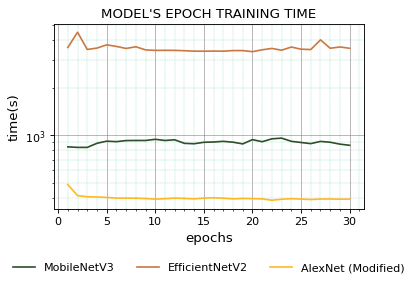

In [38]:
epochs = np.arange(1, EPOCHS + 1)
plt.figure(figsize=(5, 3), dpi=80)
plt.plot(epochs, mobilenetv3_history.epoch_train_time, label="MobileNetV3", color=PALETTES.nature[0])
plt.plot(epochs, efficientnetv2_history.epoch_train_time, label="EfficientNetV2", color=PALETTES.nature[14])
plt.plot(epochs, alexnet_history.epoch_train_time, label="AlexNet (Modified)", color=PALETTES.nature[2])
plt.title("MODEL'S EPOCH TRAINING TIME", color="k", fontsize=12)
plt.xlabel("epochs", fontsize=12)
plt.ylabel("time(s)", fontsize=12)
plt.yscale("log")

plt.minorticks_on()
plt.grid(which='major', color='gray', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='#7ED4AD', linestyle='--', linewidth=0.3)
plt.legend(loc="lower center",
    ncol=3, frameon=False, fontsize=10, title="",
    bbox_to_anchor=(0.5, -.4),
)
plt.show()

### Training and Validation Accuracy

In the following code cell, the **training** and **validation accuracies** are visualized across epochs using line plots.

This analysis helps monitor how well each model learns during training and how effectively it generalizes to unseen validation data. It also supports the identification of convergence patterns, performance improvements, and possible issues such as overfitting or underfitting.

The same accuracy visualization is applied to `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to support fair comparison across the three models.

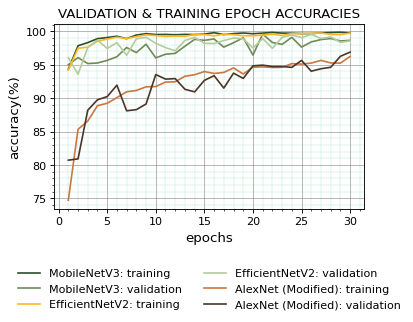

In [39]:
plt.figure(figsize=(5, 3), dpi=80)
plt.plot(epochs, [i * 100 for i in mobilenetv3_history.train_acc], label="MobileNetV3: training", color=PALETTES.nature[0])
plt.plot(epochs, [i * 100 for i in mobilenetv3_history.val_acc], label="MobileNetV3: validation", color=PALETTES.nature[1])
plt.plot(epochs, [i * 100 for i in efficientnetv2_history.train_acc], label="EfficientNetV2: training", color=PALETTES.nature[2])
plt.plot(epochs, [i * 100 for i in efficientnetv2_history.val_acc], label="EfficientNetV2: validation", color=PALETTES.nature[13])
plt.plot(epochs, [i * 100 for i in alexnet_history.train_acc], label="AlexNet (Modified): training", color=PALETTES.nature[14])
plt.plot(epochs, [i * 100 for i in alexnet_history.val_acc], label="AlexNet (Modified): validation", color=PALETTES.nature[15])

plt.title("VALIDATION & TRAINING EPOCH ACCURACIES", color="k", fontsize=12)
plt.xlabel("epochs", fontsize=12)
plt.ylabel("accuracy(%)", fontsize=12)
plt.legend(loc="lower center",
    ncol=2, frameon=False, fontsize=10, title="",
    bbox_to_anchor=(0.5, -.6),
)
plt.minorticks_on()
plt.grid(which='major', color='gray', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='#7ED4AD', linestyle='--', linewidth=0.3)
plt.show()

### Training and Validation Loss

In the following code cell, the **training** and **validation loss** values are visualized across epochs using line plots.

This analysis helps monitor the optimization process and shows how well each model is learning over time. A decreasing loss generally indicates that the model is improving, while a large gap between training and validation loss may suggest overfitting.

The same loss visualization is applied to `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to support fair comparison of convergence behavior and generalization performance.

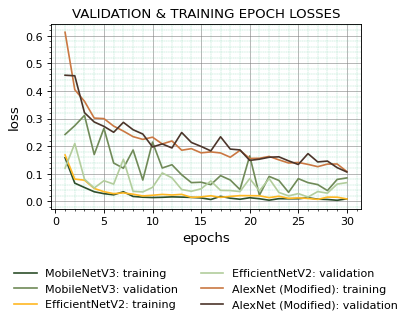

In [40]:
plt.figure(figsize=(5, 3), dpi=80)

plt.plot(epochs, mobilenetv3_history.train_losses, label="MobileNetV3: training", color=PALETTES.nature[0])
plt.plot(epochs, mobilenetv3_history.val_losses, label="MobileNetV3: validation", color=PALETTES.nature[1])
plt.plot(epochs, efficientnetv2_history.train_losses, label="EfficientNetV2: training", color=PALETTES.nature[2])
plt.plot(epochs, efficientnetv2_history.val_losses, label="EfficientNetV2: validation", color=PALETTES.nature[13])
plt.plot(epochs, alexnet_history.train_losses, label="AlexNet (Modified): training", color=PALETTES.nature[14])
plt.plot(epochs, alexnet_history.val_losses, label="AlexNet (Modified): validation", color=PALETTES.nature[15])

plt.title("VALIDATION & TRAINING EPOCH LOSSES", color="k", fontsize=12)
plt.xlabel("epochs", fontsize=12)
plt.ylabel("loss", fontsize=12)

plt.legend(loc="lower center",
    ncol=2, frameon=False, fontsize=10, title="",
    bbox_to_anchor=(0.5, -.6),
)

plt.minorticks_on()
plt.grid(which='major', color='gray', linestyle='-', linewidth=0.5)
plt.grid(which='minor', color='#7ED4AD', linestyle='--', linewidth=0.3)
plt.show()

### Best Model Evaluation

In the following code cell, a function is defined to evaluate the **best saved model checkpoint** for each architecture.

The function performs inference on the independent **test dataset** and computes key performance metrics, including **test loss**, **test accuracy**, and **inference time**. This provides an unbiased estimate of how well the trained model generalizes to unseen breast cancer images.

| Metric | Description |
|---|---|
| Test Loss | Measures the model’s error on unseen test data |
| Test Accuracy | Shows the percentage of correctly classified test images |
| Inference Time | Measures how long the model takes to make predictions |

This evaluation is applied to `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to support fair comparison of predictive performance and deployment efficiency for the **BreastGuard** application.

In [41]:
def evaluate_best_model(model, model_name, test_iterator, criterion, device):
    model.eval()
    model.load_state_dict(torch.load(model_name, weights_only=True))
    test_loss, test_acc = evaluate(model, test_iterator, criterion, device)
    return f'{test_loss:.2f}', f'{test_acc * 100:.2f}'

models = {
    "AlexNet": {
        "model": alexnet,
        "checkpoint": "alexnet.pt",
        "criterion": criterions["alexnet"],
    },
    "MobileNetV3": {
        "model": mobilenetv3,
        "checkpoint": "mobilenetv3.pt",
        "criterion": criterions["mobilenetv3"],
    },
    "EfficientNetV2": {
        "model": efficientnetv2,
        "checkpoint": "efficientnetv2.pt",
        "criterion": criterions["efficientnetv2"],
    },
}

rows = []
test_samples = n_test_examples
for model_name, model_info in models.items():
    start = time.time()
    loss, acc = evaluate_best_model(
        model_info["model"],
        model_info["checkpoint"],
        test_iterator,
        model_info["criterion"],
        device
    )
    end = time.time()
    rows.append([
        model_name,
        loss,
        acc,
        test_samples,
        hms_string(end - start)
    ])

tabulate_data(
    ["NAME", "LOSS", "ACCURACY (%)", "SAMPLES", "INFERENCE TIME"],
    rows,
    "BEST CHECKPOINTED MODEL PERFOMANCE"
)

BEST CHECKPOINTED MODEL PERFOMANCE
+----------------+------+--------------+---------+----------------+
| NAME           | LOSS | ACCURACY (%) | SAMPLES | INFERENCE TIME |
+----------------+------+--------------+---------+----------------+
| AlexNet        | 0.11 |        96.73 |    3556 |     0:01:41.60 |
| MobileNetV3    | 0.03 |        99.33 |    3556 |     0:01:36.78 |
| EfficientNetV2 | 0.01 |        99.78 |    3556 |     0:01:40.15 |
+----------------+------+--------------+---------+----------------+


### Wilson Score Confidence Interval for Model Accuracy

The **Wilson Score Confidence Interval** is used to estimate the uncertainty around the model’s test accuracy. Since accuracy represents the proportion of correctly classified samples, it can be treated as a binomial proportion.

The Wilson Score Interval is computed as:

$$
\frac{\hat{p}+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat{p}(1-\hat{p})}{n}+\frac{z^2}{4n^2}}}{1+\frac{z^2}{n}}
$$

Where:

| Symbol | Description |
|---|---|
| $\hat{p}$ | Observed model accuracy |
| $n$ | Total number of test samples |
| $z$ | Critical value from the standard normal distribution |
| $\pm$ | Represents the lower and upper confidence bounds |

The confidence intervals will be computed at three confidence levels:

| Confidence Level | Z-score |
|---|---:|
| 90% | 1.645 |
| 95% | 1.960 |
| 99% | 2.576 |

This analysis provides a more reliable estimate of model performance by showing the range within which the true accuracy is expected to fall. It is especially useful when comparing `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` on the independent test dataset.

In [42]:
def wilson_score_interval(accuracy, n, confidence=0.95):
    """
    Compute Wilson Score Confidence Interval.

    Parameters:
    accuracy (float): Model accuracy between 0 and 1
    n (int): Number of test samples
    confidence (float): Confidence level (default = 0.95)

    Returns:
    tuple: (lower_bound, upper_bound)
    """
    z_values = {
        0.90: 1.645,
        0.95: 1.96,
        0.99: 2.576
    }
    z = z_values.get(confidence, 1.96)
    denominator = 1 + (z**2 / n)
    centre = accuracy + (z**2 / (2 * n))
    margin = z * math.sqrt(
        (accuracy * (1 - accuracy) / n) +
        (z**2 / (4 * n**2))
    )
    lower = (centre - margin) / denominator
    upper = (centre + margin) / denominator
    return lower, upper

### Wilson Score Confidence Intervals for All Models

In the following code cell, the **90%**, **95%**, and **99%** confidence intervals are computed for the testing accuracies of all three models using the **Wilson Score Interval** method.

The models evaluated are:

- `MobileNetV3`
- `EfficientNetV2`
- Modified `AlexNet`

This analysis provides a statistical estimate of the reliability of each model’s observed test accuracy by showing the range within which the true accuracy is expected to fall at different confidence levels.

| Model | Confidence Intervals Computed |
|---|---|
| `MobileNetV3` | 90%, 95%, and 99% |
| `EfficientNetV2` | 90%, 95%, and 99% |
| Modified `AlexNet` | 90%, 95%, and 99% |

These confidence intervals support a more reliable comparison of model performance on the independent breast cancer test dataset.

In [43]:
confidence_levels = [0.90, 0.95, 0.99]

for confidence in confidence_levels:
    ci_rows = []

    for row in rows:
        model_name = row[0]
        acc = float(row[2]) / 100.0
        n = int(row[3])

        lower, upper = wilson_score_interval(
            acc,
            n,
            confidence=confidence
        )

        ci_rows.append([
            model_name,
            f"{acc * 100:.2f}",
            f"{lower * 100:.2f}",
            f"{upper * 100:.2f}",
        ])

    tabulate_data(
        ["NAME", "Accuracy (%)", "Lower CI (%)", "Upper CI (%)"],
        ci_rows,
        f"{int(confidence * 100)}% CONFIDENCE INTERVAL"
    )

    print("\n")

90% CONFIDENCE INTERVAL
+----------------+--------------+--------------+--------------+
| NAME           | Accuracy (%) | Lower CI (%) | Upper CI (%) |
+----------------+--------------+--------------+--------------+
| AlexNet        |        96.73 |        96.20 |        97.19 |
| MobileNetV3    |        99.33 |        99.06 |        99.52 |
| EfficientNetV2 |        99.78 |        99.61 |        99.88 |
+----------------+--------------+--------------+--------------+


95% CONFIDENCE INTERVAL
+----------------+--------------+--------------+--------------+
| NAME           | Accuracy (%) | Lower CI (%) | Upper CI (%) |
+----------------+--------------+--------------+--------------+
| AlexNet        |        96.73 |        96.09 |        97.27 |
| MobileNetV3    |        99.33 |        99.00 |        99.55 |
| EfficientNetV2 |        99.78 |        99.56 |        99.89 |
+----------------+--------------+--------------+--------------+


99% CONFIDENCE INTERVAL
+----------------+----------

### Model Evaluation Metrics

In this section, the performance of the breast cancer classification models is evaluated using standard classification metrics. Since this study is a **binary classification** task, the evaluation focuses on how well each model distinguishes between `benign` and `malignant` breast cancer images.

The three models evaluated are `MobileNetV3`, `EfficientNetV2`, and the modified `AlexNet`. Predictions are generated on the independent **test dataset** to ensure that performance is assessed on unseen data.

The following evaluation tools are used:

| Evaluation Tool | Purpose |
|---|---|
| Confusion Matrix | Shows the number of correct and incorrect predictions for the `benign` and `malignant` classes |
| Classification Report | Provides precision, recall, F1-score, and support for each class |
| Accuracy | Measures the overall proportion of correctly classified test images |
| Inference Time | Measures prediction speed and supports deployment analysis |

These metrics are computed consistently across all three models to support a fair comparison of classification performance, generalization ability, and suitability for integration into the **BreastGuard** mHealth application.


In [44]:
def get_predictions(model, iterator, device):
  model.eval()
  images = []
  labels = []
  probs = []
  with torch.no_grad():
    for (x, y) in iterator:
      x = x.to(device)
      y_pred = model(x)
      y_prob = F.sigmoid(y_pred).squeeze().detach()
      images.append(x.cpu())
      labels.append(y.cpu())
      probs.append(y_prob)
  images = torch.cat(images, dim = 0)
  labels = torch.cat(labels, dim = 0)
  probs = torch.cat(probs, dim = 0)
  return images, labels, probs

mobilenetv3_test_images, mobilenetv3_test_labels, mobilenetv3_probs = get_predictions(mobilenetv3, test_iterator, device)
efficientnetv2_test_images, efficientnetv2_test_labels, efficientnetv2_probs = get_predictions(efficientnetv2, test_iterator, device)
alexnet_test_images, alexnet_test_labels, alexnet_probs = get_predictions(alexnet, test_iterator, device)

### Converting Model Probabilities to Binary Predictions

Since this is a **binary classification** task with one output node, the model outputs are converted into class predictions using a threshold-based approach instead of `argmax`.

The predicted probabilities are rounded to obtain binary class labels:

| Probability Range | Predicted Class |
|---|---:|
| `< 0.5` | 0 |
| `≥ 0.5` | 1 |

In this project, the binary labels represent the two breast cancer classes: `benign` and `malignant`. This conversion is applied consistently to the outputs of `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` before computing evaluation metrics such as the confusion matrix and classification report.

In [45]:
mobilenetv3_preds = torch.round(mobilenetv3_probs).cpu().numpy().astype(np.int32)
mobilenetv3_test_labels = mobilenetv3_test_labels.cpu().numpy().astype(np.int32)

efficientnetv2_preds = torch.round(efficientnetv2_probs).cpu().numpy().astype(np.int32)
efficientnetv2_test_labels = efficientnetv2_test_labels.cpu().numpy().astype(np.int32)

alexnet_preds = torch.round(alexnet_probs).cpu().numpy().astype(np.int32)
alexnet_test_labels = alexnet_test_labels.cpu().numpy().astype(np.int32)

### Plotting Predictions

In this section, a qualitative evaluation is performed by visualizing selected breast cancer images together with their true labels and predicted labels.

This analysis helps inspect whether each model correctly classifies samples as `benign` or `malignant`. It also supports the identification of misclassified cases and provides a clearer understanding of model behavior at the image level.

The prediction visualization is applied to `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to compare their qualitative performance on the breast cancer test dataset.

In [46]:
def get_predictions_labels(test_images, preds, test_labels):
    test_images_labels = list(zip(test_images, preds, test_labels))
    random.shuffle(test_images_labels)
    y_true = []
    y_pred = []
    images = []
    for img, pred, label in test_images_labels[:24]:
      y_true.append(label)
      y_pred.append(pred)
      images.append(img)
    
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return images, y_true, y_pred
    
mobilenetv3_images, mobilenetv3_y_true, mobilenetv3_y_pred = get_predictions_labels(
    mobilenetv3_test_images, mobilenetv3_preds, mobilenetv3_test_labels
)
efficientnetv2_images, efficientnetv2_y_true, efficientnetv2_y_pred = get_predictions_labels(
    efficientnetv2_test_images, efficientnetv2_preds, efficientnetv2_test_labels
)
alexnet_images, alexnet_y_true, alexnet_y_pred = get_predictions_labels(
    alexnet_test_images, alexnet_preds, alexnet_test_labels
)

Next we are going to define the function that will plot the predictions for us.

In [47]:
def plot_predictions_images(images_and_classes,
                            labels_true, labels_pred,
                            cols=5):
    rows = 3
    fig = plt.figure(dpi=80)
    fig.set_size_inches(cols * 2, rows * 2)
    for i, (image, label_true, label_pred) in enumerate(zip(images_and_classes, labels_true.astype("int32"), labels_pred)):
        plt.subplot(rows, cols, i + 1)
        plt.axis('off')
        image = normalize_image(image)
        plt.imshow(image.permute(1, 2, 0).cpu().numpy(), cmap="gray")
        plt.title(class_names[label_pred], color ='g' if label_true == label_pred else 'r', fontsize=10 )

### Visualizing Model Predictions

Next, the predictions produced by the three breast cancer classification models are visualized on selected samples from the test dataset. The models evaluated are `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

This qualitative prediction analysis helps assess how well each model classifies breast cancer images into the correct class: `benign` or `malignant`. By comparing the predicted labels with the actual labels, this step highlights correctly classified samples and potential misclassifications.

The visualization provides additional insight beyond numerical metrics by showing how each model performs on unseen breast cancer images. Correct predictions indicate cases where the model successfully learned relevant histopathology patterns, while incorrect predictions help identify samples that may be visually difficult to classify.

This analysis supports the comparative evaluation of `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` by providing a visual understanding of their prediction behavior on the independent test dataset.

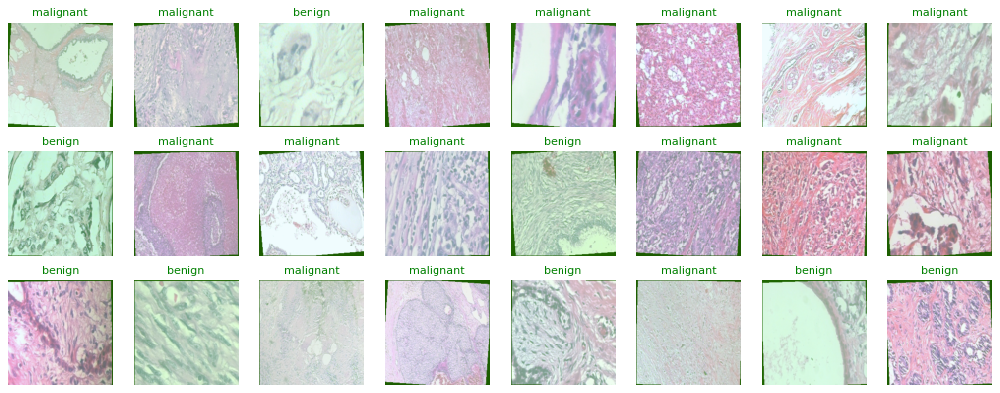

In [48]:
plot_predictions_images(
    mobilenetv3_images[:24],
    mobilenetv3_y_true[:24],
    mobilenetv3_y_pred[:24],
    cols=8
)

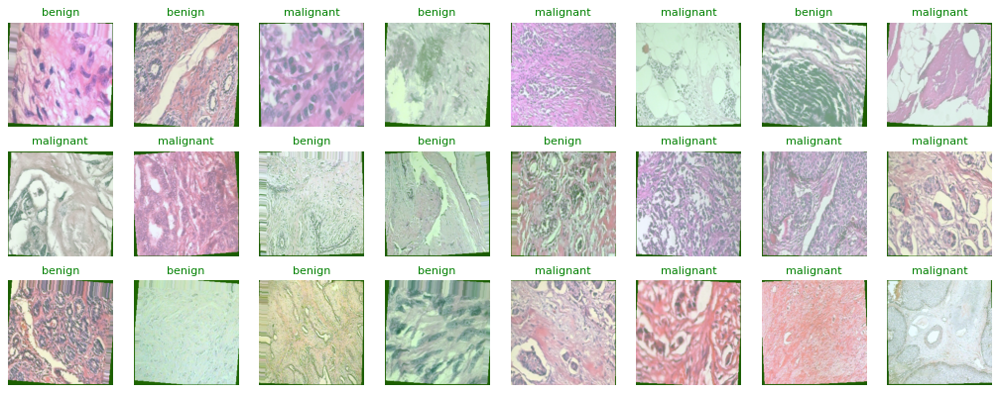

In [49]:
plot_predictions_images(
    efficientnetv2_images[:24],
    efficientnetv2_y_true[:24],
    efficientnetv2_y_pred[:24],
    cols=8
)

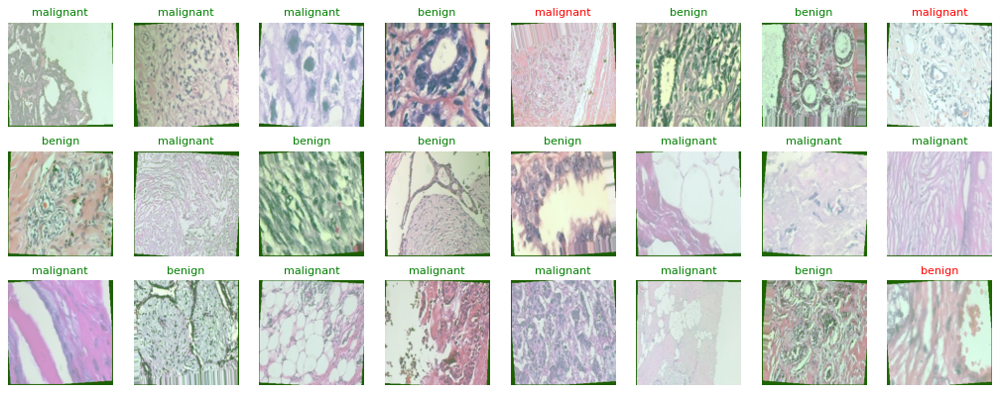

In [50]:
plot_predictions_images(
    alexnet_images[:24],
    alexnet_y_true[:24],
    alexnet_y_pred[:24],
    cols=8
)

### Confusion Matrix

In the following code cell, the **confusion matrix** is computed and visualized using predictions from the held-out **test dataset**.

Since this is a **binary classification** task, the confusion matrix summarizes the number of correct and incorrect predictions for the `benign` and `malignant` classes. It captures the distribution of:

| Term | Meaning |
|---|---|
| True Positive | Positive class correctly predicted |
| True Negative | Negative class correctly predicted |
| False Positive | Negative class incorrectly predicted as positive |
| False Negative | Positive class incorrectly predicted as negative |

This analysis provides a detailed view of model performance beyond accuracy by showing the types of errors made by each model. The confusion matrix is generated for `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to support fair comparison across all models.

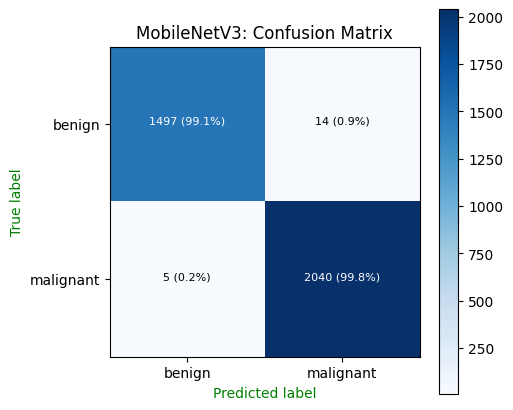

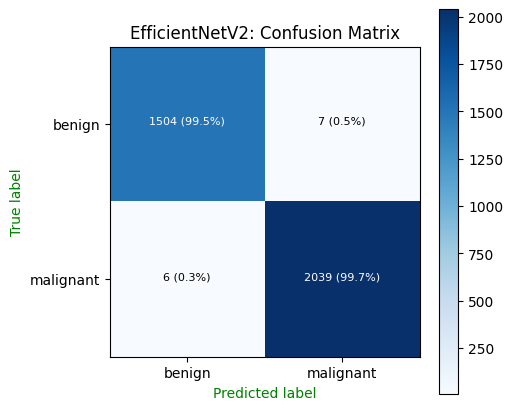

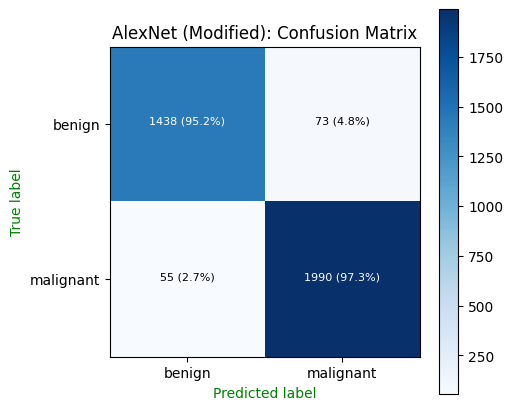

In [51]:
plot_complicated_confusion_matrix(
    mobilenetv3_test_labels,
    mobilenetv3_preds,
    class_names,
    fontsize=8,
    figsize=(5, 5),
    title="MobileNetV3: Confusion Matrix"
)
plot_complicated_confusion_matrix(
    efficientnetv2_test_labels,
    efficientnetv2_preds,
    class_names,
    fontsize=8,
     figsize=(5, 5),
    title="EfficientNetV2: Confusion Matrix"
)
plot_complicated_confusion_matrix(
    alexnet_test_labels,
    alexnet_preds,
    class_names,
    fontsize=8,
     figsize=(5, 5),
    title="AlexNet (Modified): Confusion Matrix"
)

### Classification Report

In the following code cell, the **classification report** is computed using predictions from the held-out **test dataset**.

The report provides a detailed evaluation of model performance for the two breast cancer classes: `benign` and `malignant`. It includes key metrics such as **precision**, **recall**, **F1-score**, and **support**.

| Metric | Description |
|---|---|
| Precision | Measures how many predicted positive samples were correctly classified |
| Recall | Measures how many actual positive samples were correctly identified |
| F1-score | Harmonic mean of precision and recall |
| Support | Number of true samples for each class |

This report helps evaluate how well each model performs on individual classes, especially in the presence of class imbalance. The classification report is generated for `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to support fair comparison across all models.

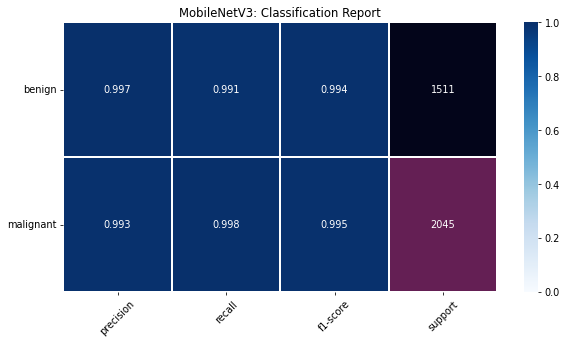

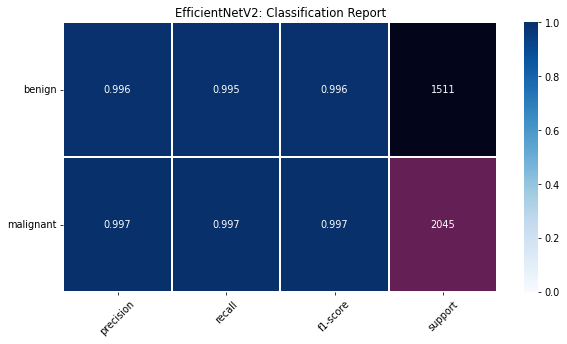

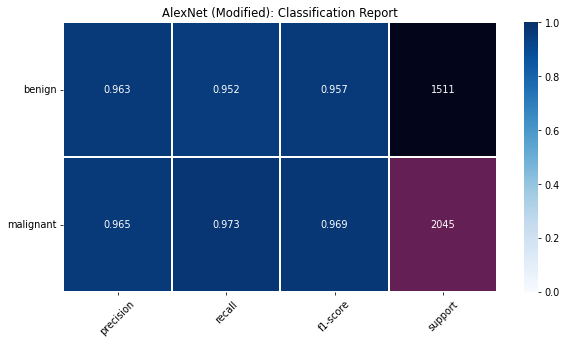

In [52]:
fig, ax = visualization.plot_classification_report(
    mobilenetv3_test_labels,
    mobilenetv3_preds,
    title='MobileNetV3: Classification Report',
    figsize=(10, 5),
    dpi=70,
    target_names=class_names
)

fig, ax = visualization.plot_classification_report(
    efficientnetv2_test_labels,
    efficientnetv2_preds,
    title='EfficientNetV2: Classification Report',
    figsize=(10, 5),
    dpi=70,
    target_names=class_names
)

fig, ax = visualization.plot_classification_report(
    alexnet_test_labels,
    alexnet_preds,
    title='AlexNet (Modified): Classification Report',
    figsize=(10, 5),
    dpi=70,
    target_names=class_names
)

### Misclassified Samples

In this section, a qualitative analysis of **misclassified samples** is performed by visualizing test images where the predicted labels do not match the true labels.

This analysis helps identify challenging breast cancer images that may be difficult for the models to classify correctly. It also provides insight into possible sources of error, such as visual similarity between `benign` and `malignant` samples, image quality variation, or ambiguous histopathology patterns.

The misclassified samples are examined for `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` to better understand each model’s weaknesses and support a more detailed comparison beyond numerical metrics.

In [53]:
mobilenetv3_corrects = torch.eq(
    torch.from_numpy(mobilenetv3_test_labels),
    torch.from_numpy(mobilenetv3_preds)
)

efficientnetv2_corrects = torch.eq(
    torch.from_numpy(efficientnetv2_test_labels),
    torch.from_numpy(efficientnetv2_preds)
)

alexnet_corrects = torch.eq(
    torch.from_numpy(alexnet_test_labels),
    torch.from_numpy(alexnet_preds)
)

In [81]:
def get_incorrect_examples(images, labels, probs, preds, corrects):
    incorrect_examples = []
    for image, label, prob, pred, correct in zip(images, labels, probs, preds, corrects):
        if not bool(correct):
            pred_label = int(pred)
            pred_prob = float(torch.max(torch.as_tensor(prob)))
            incorrect_examples.append((
                image,
                int(label),
                pred_label,
                pred_prob
            ))
    incorrect_examples = sorted(
        incorrect_examples,
        key=lambda x: x[3],
        reverse=True
    )
    return incorrect_examples

incorrect_examples = {
    "mobilenetv3": get_incorrect_examples(
        mobilenetv3_test_images,
        mobilenetv3_test_labels,
        mobilenetv3_probs,
        mobilenetv3_preds,
        mobilenetv3_corrects
    ),
    "efficientnetv2": get_incorrect_examples(
        efficientnetv2_test_images,
        efficientnetv2_test_labels,
        efficientnetv2_probs,
        efficientnetv2_preds,
        efficientnetv2_corrects
    ),
    "alexnet": get_incorrect_examples(
        alexnet_test_images,
        alexnet_test_labels,
        alexnet_probs,
        alexnet_preds,
        alexnet_corrects
    ),
}

In [82]:
def plot_most_incorrect(incorrect, classes, n_images, normalize=True):
    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))
    fig = plt.figure(figsize=(6, 4), dpi=100)
    for i in range(min(rows * cols, len(incorrect))):
        ax = fig.add_subplot(rows, cols, i + 1)
        image, true_label, pred_label, prob = incorrect[i]
        image = image.permute(1, 2, 0)
        true_label = int(true_label)
        pred_label = int(pred_label)

        true_class = classes[true_label]
        predicted_class = classes[pred_label]
        if normalize:
            image = normalize_image(image)
        ax.imshow(image.cpu().numpy())
        ax.set_title(
            f"Real: {true_class}\n"
            f"Predicted: {predicted_class} \n({prob * 100:.0f}%)",
            fontsize=8
        )
        ax.axis("off")

    fig.subplots_adjust(hspace=0.6)
    plt.show()

In the following code cell, we present the **most frequently misclassified samples** based on the model's predictions. This targeted analysis supports the identification of systematic errors and provides deeper insight into the model's failure modes.


MobileNetV3 Most Incorrect Predictions:


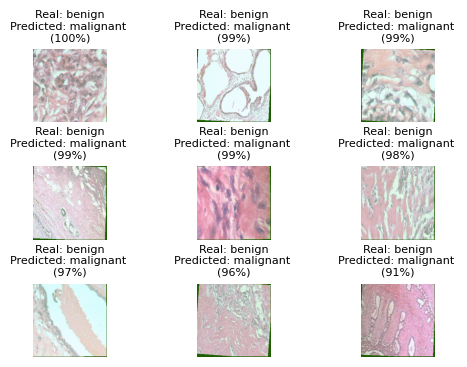


EfficientNetV2 Most Incorrect Predictions:


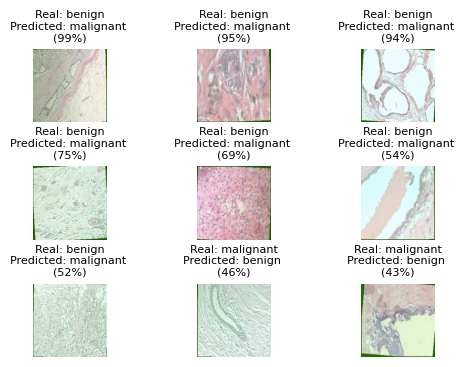


AlexNet (Modified) Most Incorrect Predictions:


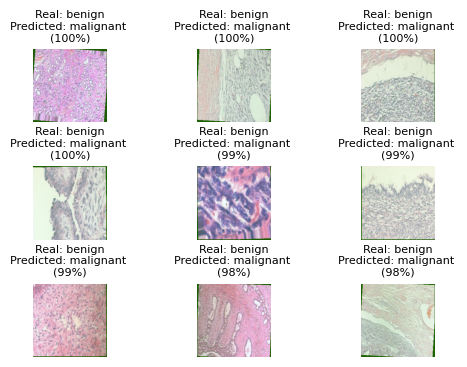

In [83]:
N_IMAGES = 12

model_titles = {
    "mobilenetv3": "MobileNetV3",
    "efficientnetv2": "EfficientNetV2",
    "alexnet": "AlexNet (Modified)"
}

for model_name, model_incorrect_examples in incorrect_examples.items():
    print(f"\n{model_titles[model_name]} Most Incorrect Predictions:")
    if len(model_incorrect_examples) == 0:
        print(f"No incorrectly predicted images for {model_titles[model_name]}")
        continue
    try:
        plot_most_incorrect(
            model_incorrect_examples,
            class_names,
            N_IMAGES
        )
    except Exception as e:
        print(f"Could not plot incorrect predictions for {model_titles[model_name]}")
        print(e)

### Grad-CAM for Qualitative Misclassification Analysis

Gradient-weighted Class Activation Mapping (**Grad-CAM**) is used to visualize the image regions that most strongly influence the predictions of a convolutional neural network. It generates a heatmap by using gradients from a selected convolutional layer, helping identify which areas of an image contributed most to the model’s decision.

In this notebook, Grad-CAM is applied to the trained `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` models during inference. It is used only for **qualitative interpretation** and does not involve additional training.

The main purpose of this analysis is to examine **misclassified breast cancer images** from the test dataset. By visualizing the Grad-CAM heatmaps, we can assess whether each model focuses on meaningful histopathology regions or whether misclassifications may be influenced by irrelevant image areas, background patterns, staining variations, or ambiguous tissue structures.

Grad-CAM is especially useful in this study because it supports explainability for the **BreastGuard** system. For each misclassified sample, the original image, heatmap, and overlay visualization are examined to better understand the prediction behavior of `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

In [114]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.fwd_hook = target_layer.register_forward_hook(self.save_activations)
        self.bwd_hook = target_layer.register_full_backward_hook(self.save_gradients)

    def save_activations(self, module, inp, out):
        self.activations = out.detach().clone()

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach().clone()

    def generate(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(x)

        if isinstance(output, tuple):
            output = output[0]

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        if isinstance(class_idx, torch.Tensor):
            class_idx = int(class_idx.detach().cpu().item())
        
        if output.shape[1] == 1:
            if class_idx == 1:
                score = output[:, 0].sum()
            else:
                score = (-output[:, 0]).sum()
        else:
            score = output[:, class_idx].sum()
        score.backward(retain_graph=True)

        if self.activations is None:
            raise RuntimeError("Activations were not captured. Check the selected target layer.")

        if self.gradients is None:
            raise RuntimeError("Gradients were not captured. Check the selected target layer.")

        grads = self.gradients[0]       # [C, H, W]
        acts = self.activations[0]      # [C, H, W]

        weights = grads.mean(dim=(1, 2), keepdim=True)  # [C, 1, 1]

        cam = (weights * acts).sum(dim=0)
        cam = F.relu(cam)

        cam_min = cam.min()
        cam_max = cam.max()

        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.detach().cpu().numpy(), class_idx

    def remove_hooks(self):
        self.fwd_hook.remove()
        self.bwd_hook.remove()

### Initializing Grad-CAM Objects

In the following code cell, **Grad-CAM objects** are initialized for `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

These objects extract class-discriminative activation maps from selected convolutional layers of each model. The activation maps help visualize which spatial regions most strongly influenced each model’s prediction.

In this breast cancer classification task, Grad-CAM is used to assess whether the models focus on meaningful histopathology regions when classifying images as `benign` or `malignant`. This supports qualitative explainability analysis, especially for misclassified test samples.

In [115]:
def replace_relu_inplace(module):
    for name, child in module.named_children():
        if isinstance(child, nn.ReLU):
            setattr(module, name, nn.ReLU(inplace=False))
        else:
            replace_relu_inplace(child)
    return module
    
mobilenetv3 = replace_relu_inplace(mobilenetv3)
efficientnetv2 = replace_relu_inplace(efficientnetv2)
alexnet = replace_relu_inplace(alexnet)

mobilenetv3.to(device).eval()
efficientnetv2.to(device).eval()
alexnet.to(device).eval()
print()

In [116]:
mobilenetv3_target_layer = mobilenetv3.features[-2]
efficientnetv2_target_layer = efficientnetv2.features[-2]
alexnet_target_layer = alexnet.features[10]

### Grad-CAM for Qualitative Breast Cancer Analysis

Grad-CAM is used to visualize the image regions that most strongly influence the predictions of `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` when classifying breast cancer images as `benign` or `malignant`.

In this notebook, Grad-CAM is applied after training to interpret selected test predictions, especially misclassified samples. The heatmaps help assess whether the models focus on meaningful histopathology regions or whether predictions are influenced by irrelevant areas, staining variations, background patterns, or ambiguous tissue structures.

This qualitative analysis complements the quantitative evaluation metrics by providing visual insight into how each model makes classification decisions. By comparing Grad-CAM outputs across the three models, the study can better assess model interpretability, reliability, and suitability for integration into the **BreastGuard** application.

In [117]:
def tensor_to_numpy_image(image):
    """
    Convert a PyTorch tensor image to a NumPy image for plotting.

    Supports image tensors in shape:
    - [C, H, W]
    - [H, W, C]
    """
    if isinstance(image, torch.Tensor):
        image = image.detach().cpu()

    if image.ndim == 3:
        if image.shape[0] in [1, 3]:
            image = image.permute(1, 2, 0)
    image = image.numpy() if isinstance(image, torch.Tensor) else image
    image = image.astype(np.float32)
    image = (image - image.min()) / (image.max() - image.min() + 1e-8)
    if image.ndim == 3 and image.shape[-1] == 1:
        image = image.squeeze(-1)
    return image

def resize_cam_to_image(cam, image):
    """
    Resize a Grad-CAM heatmap to match the image height and width.
    """
    if isinstance(cam, torch.Tensor):
        cam = cam.detach().cpu().float()
    cam = np.array(cam, dtype=np.float32)
    if isinstance(image, torch.Tensor):
        if image.ndim == 3:
            h, w = image.shape[-2], image.shape[-1]
        else:
            h, w = image.shape
    else:
        h, w = image.shape[:2]

    if cam.shape != (h, w):
        cam_tensor = torch.tensor(cam).unsqueeze(0).unsqueeze(0)
        cam_tensor = F.interpolate(
            cam_tensor,
            size=(h, w),
            mode="bilinear",
            align_corners=False
        )
        cam = cam_tensor.squeeze().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam

def gradcam_bbox(cam, threshold=0.55):
    """
    Generate a bounding box around the most activated Grad-CAM region.
    """
    mask = cam >= threshold
    if mask.sum() == 0:
        return None
    y_indices, x_indices = np.where(mask)
    x_min = x_indices.min()
    x_max = x_indices.max()
    y_min = y_indices.min()
    y_max = y_indices.max()
    return x_min, y_min, x_max, y_max

### Binary Prediction Function

In the following code cell, a `predict_binary` function is defined to generate predictions for the binary breast cancer classification task.

Since each model produces one output score, the sigmoid function is applied to convert the output into a probability. A threshold of `0.5` is then used to assign the final class label.

| Probability | Predicted Class |
|---|---:|
| `< 0.5` | 0 |
| `≥ 0.5` | 1 |

The function returns both the predicted class label and the confidence score. This is useful for visualizing predictions and interpreting how confident each model is when classifying images as `benign` or `malignant`.

In [118]:
def predict_binary(model, x, threshold=0.5):
    """
    Predict the class label and confidence score for a binary classification model.
    """
    model.eval()
    with torch.no_grad():
        output = model(x)

        if isinstance(output, tuple):
            output = output[0]
        prob = torch.sigmoid(output).item()
        pred = int(prob >= threshold)
        confidence = prob if pred == 1 else 1 - prob
    return pred, confidence

### Safe Integer Conversion Helper

In the following code cell, a `_safe_to_int` helper function is defined to safely convert labels or predictions into integer values.

This is useful because labels and predictions may be stored as PyTorch tensors, NumPy values, or standard Python values. For the binary classification task, the function ensures that values are converted into scalar integer labels, typically `0` or `1`, before visualization or comparison.

This helper supports consistent handling of predictions and ground-truth labels when plotting breast cancer classification results for `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

In [119]:
def _safe_to_int(value):
    """
    Safely convert tensors, NumPy values, or Python values to int.
    Designed for binary classification labels or predictions.
    """
    if isinstance(value, torch.Tensor):
        value = value.detach().cpu().view(-1)
        if value.numel() == 1:
            return int(value.item())
        return int(torch.round(value[0]).item())
    return int(value)

### Grad-CAM Original, Heatmap, and Bounding Box Visualization

The `plot_gradcam_original_cam_bbox_grid` function is used to visualize the **original breast cancer image**, its corresponding **Grad-CAM heatmap**, and the **Grad-CAM-based bounding box** in a structured grid format.

This function supports qualitative explainability analysis for the **BreastGuard breast cancer classification** task. By displaying the original image, activation map, and highlighted attention region side by side, it helps assess whether `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` focus on meaningful histopathology regions when making predictions.

The Grad-CAM heatmap highlights image regions that contribute most strongly to the predicted class, while the bounding box provides a simplified visual indication of the most activated area. This is especially useful for analyzing misclassified samples, as it helps identify whether incorrect predictions may be linked to relevant tissue patterns, ambiguous visual structures, staining variations, or irrelevant image regions.

Overall, this visualization complements the quantitative evaluation by providing insight into the interpretability and decision-making behavior of the three models for automated breast cancer image classification.

In [120]:
def plot_gradcam_original_cam_bbox_grid(
    samples,
    gradcam,
    class_names,
    device,
    samples_per_row=2,
    show_bbox=True,
    bbox_threshold=0.55,
    dpi=300,
    save_path=None
):
    """
    Plot original image, Grad-CAM heatmap, and Grad-CAM overlay with bounding box.

    Each sample must be either:
    - (image, true_label, pred_label)
    - (image, true_label, pred_label, prob)
    """

    n_images = len(samples)

    if n_images == 0:
        print("No samples available for Grad-CAM visualization.")
        return

    panels_per_sample = 3
    total_cols = samples_per_row * panels_per_sample
    rows = int(np.ceil(n_images / samples_per_row))

    fig, axes = plt.subplots(
        rows,
        total_cols,
        figsize=(total_cols * 2.2, rows * 2.7),
        dpi=dpi
    )

    axes = np.array(axes).reshape(rows, total_cols)

    for i, sample in enumerate(samples):
        if len(sample) == 3:
            image, true_label, pred_label = sample
            prob = None

        elif len(sample) == 4:
            image, true_label, pred_label, prob = sample

        else:
            raise ValueError(
                "Each sample must be either "
                "(image, true_label, pred_label) or "
                "(image, true_label, pred_label, prob)."
            )

        true_label = _safe_to_int(true_label)
        pred_label = _safe_to_int(pred_label)

        row_idx = i // samples_per_row
        sample_pos = i % samples_per_row
        col_start = sample_pos * panels_per_sample

        if isinstance(image, torch.Tensor):
            x = image.unsqueeze(0).to(device)
        else:
            x = torch.tensor(image).permute(2, 0, 1).unsqueeze(0).float().to(device)

        cam, explained_class = gradcam.generate(
            x,
            class_idx=pred_label
        )

        explained_class = _safe_to_int(explained_class)

        img = tensor_to_numpy_image(image)
        cam = resize_cam_to_image(cam, image)

        ax = axes[row_idx, col_start]
        ax.imshow(img)
        ax.set_title(
            f"Original\nTrue: {class_names[true_label]}",
            fontsize=8,
            fontweight="bold",
            color="black"
        )
        ax.axis("off")

        ax = axes[row_idx, col_start + 1]
        ax.imshow(cam, cmap="jet")
        ax.set_title(
            f"Grad-CAM\nPred: {class_names[explained_class]}",
            fontsize=8,
            fontweight="bold",
            color="black"
        )
        ax.axis("off")

        ax = axes[row_idx, col_start + 2]
        ax.imshow(img)

        cam_masked = np.ma.masked_where(cam < 0.25, cam)
        ax.imshow(cam_masked, cmap="jet", alpha=0.6)

        if show_bbox:
            bbox = gradcam_bbox(cam, threshold=bbox_threshold)
            if bbox is not None:
                x_min, y_min, x_max, y_max = bbox
                rect = patches.Rectangle(
                    (x_min, y_min),
                    x_max - x_min,
                    y_max - y_min,
                    linewidth=2,
                    edgecolor="yellow",
                    facecolor="none"
                )

                ax.add_patch(rect)

        if prob is not None:
            title = f"Overlay + BBox\nConf: {prob:.2f}"
        else:
            title = "Overlay + BBox"

        ax.set_title(
            title,
            fontsize=8,
            fontweight="bold",
            color="black"
        )
        ax.axis("off")
    used_panels = n_images * panels_per_sample
    total_panels = rows * total_cols
    flat_axes = axes.reshape(-1)
    for j in range(used_panels, total_panels):
        flat_axes[j].axis("off")
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=dpi,
            bbox_inches="tight",
            pad_inches=0.05
        )
    plt.show()

### Grad-CAM Explanation for Sample Predictions

In the following code cell, a sample of **12 model predictions** is explained using Grad-CAM.

For each breast cancer image, the visualization displays the **original image**, the corresponding **Grad-CAM heatmap**, and the **highlighted region** that contributed most strongly to the model’s predicted class.

This visualization is applied to the trained `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` models to support qualitative comparison of their decision-making behavior. By examining the highlighted regions, we can assess whether each model focuses on meaningful histopathology patterns rather than irrelevant image regions.

For misclassified samples, this analysis helps identify whether incorrect predictions may be caused by attention to non-informative regions, ambiguous tissue structures, staining variations, or visually similar patterns between `benign` and `malignant` samples.

In [121]:
gradcam_mobilenetv3 = GradCAM(mobilenetv3, mobilenetv3_target_layer)
gradcam_efficientnetv2 = GradCAM(efficientnetv2, efficientnetv2_target_layer)
gradcam_alexnet = GradCAM(alexnet, alexnet_target_layer)


MobileNetV3 Grad-CAM on Most Incorrect Predictions


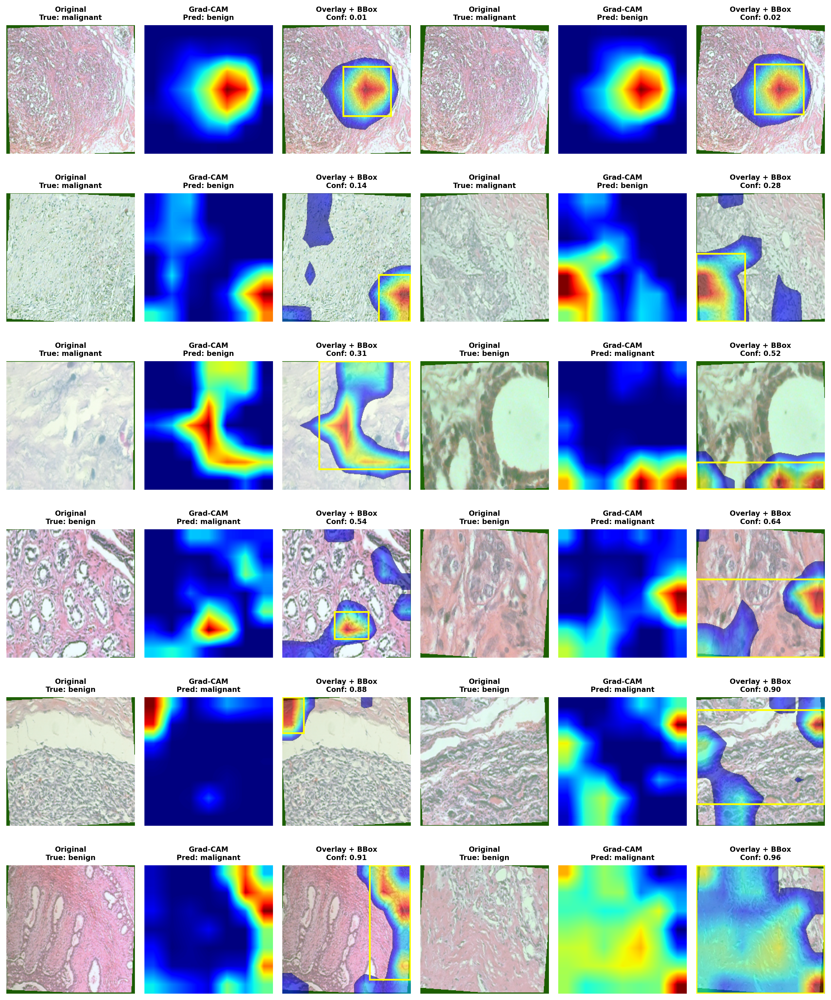


EfficientNetV2 Grad-CAM on Most Incorrect Predictions


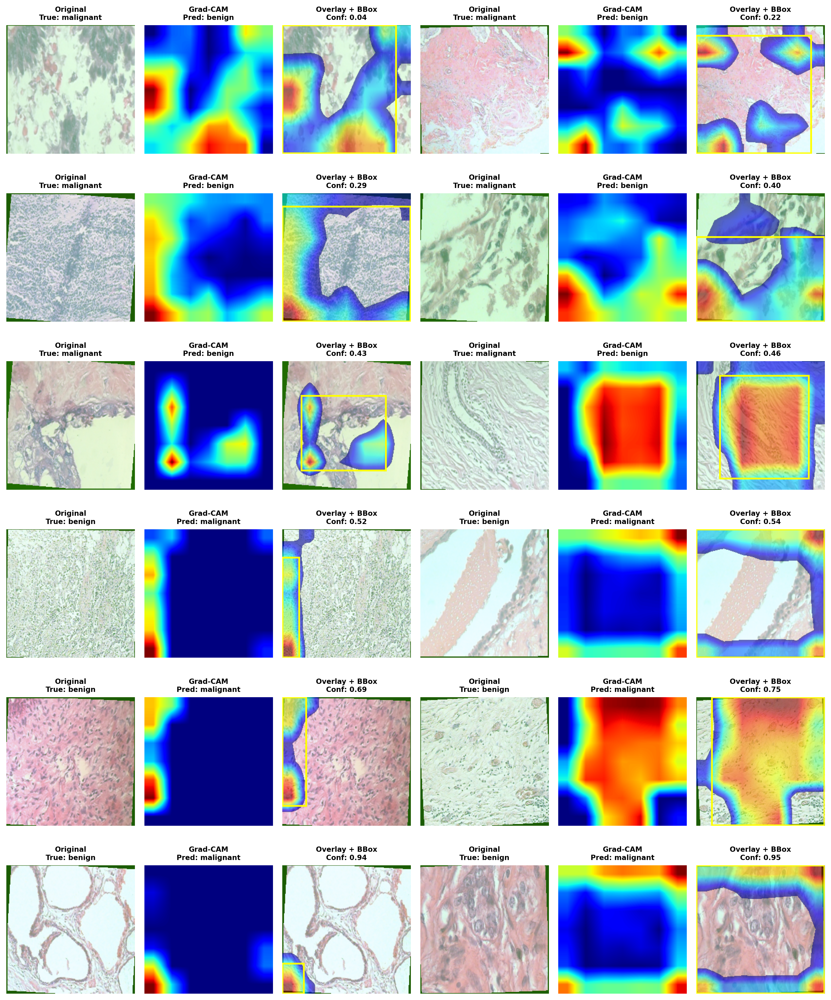


AlexNet (Modified) Grad-CAM on Most Incorrect Predictions


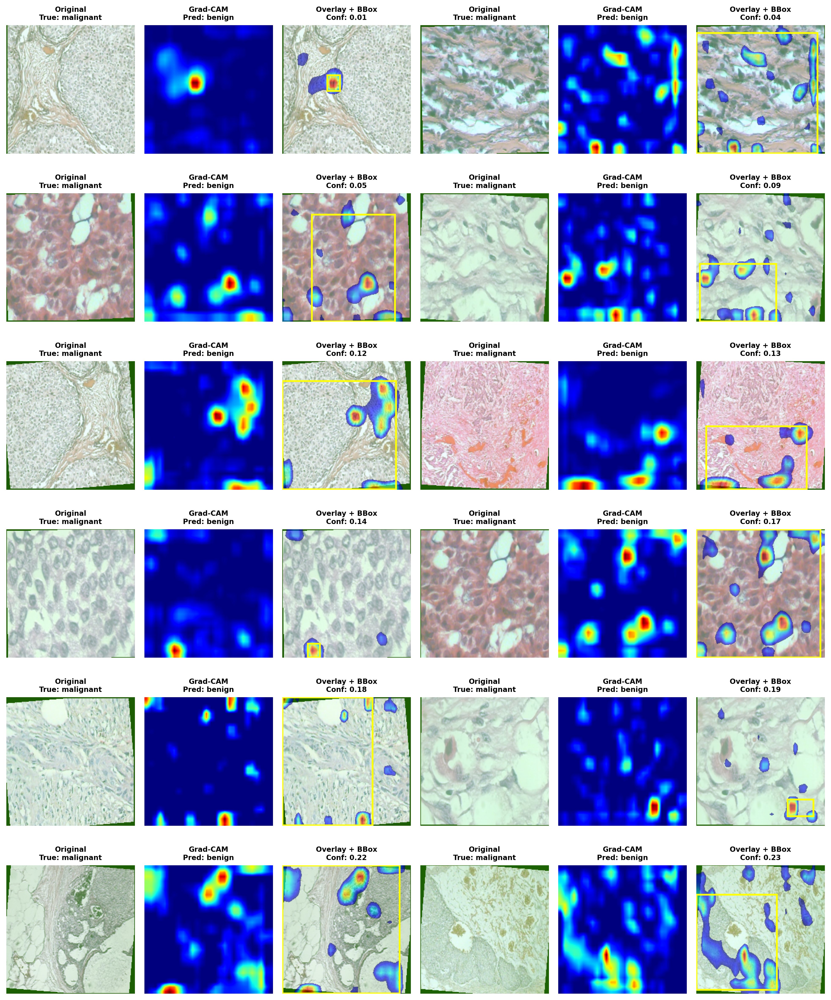

In [122]:
N_IMAGES = 12

model_gradcams = {
    "mobilenetv3": gradcam_mobilenetv3,
    "efficientnetv2": gradcam_efficientnetv2,
    "alexnet": gradcam_alexnet
}

model_titles = {
    "mobilenetv3": "MobileNetV3",
    "efficientnetv2": "EfficientNetV2",
    "alexnet": "AlexNet (Modified)"
}

for model_name, model_incorrect_examples in incorrect_examples.items():
    print(f"\n{model_titles[model_name]} Grad-CAM on Most Incorrect Predictions")
    samples = model_incorrect_examples[::-1][:N_IMAGES]
    if len(samples) == 0:
        print(f"No incorrect predictions found for {model_titles[model_name]}.")
        continue
    plot_gradcam_original_cam_bbox_grid(
        samples=samples,
        gradcam=model_gradcams[model_name],
        class_names=class_names,
        device=device,
        samples_per_row=2,
        show_bbox=True,
        bbox_threshold=0.55,
        dpi=300,
        save_path=f"{model_name}_gradcam_incorrect_predictions.png"
    )

### Model Sizes

In the following code cell, the saved model size is calculated for each trained model: `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

This analysis helps determine the disk storage requirements of each model checkpoint and supports deployment planning for the **BreastGuard** application.

| Model | Model Size | Purpose |
|---|---:|---|
| `MobileNetV3` | To be computed | Assesses storage efficiency for mobile deployment |
| `EfficientNetV2` | To be computed | Assesses storage cost of a higher-capacity model |
| Modified `AlexNet` | To be computed | Assesses storage requirements of the baseline CNN |

Model size is important because smaller models are generally easier to deploy, transfer, and load in resource-constrained environments, while larger models may require more storage and memory during deployment.

In [123]:
def model_size(path: str):
    num = os.path.getsize(path)
    for unit in ['bytes', 'KB', 'MB', 'GB', 'TB']:
        if num < 1024.0:
            return f"{num:.1f} {unit}"
        num /= 1024.0

tabulate_data(
    ["Model", "Size"],
    [
        ["MobileNetV3", model_size("mobilenetv3.pt")],
        ["EfficientNetV2", model_size("efficientnetv2.pt")],
        ["Modified AlexNet", model_size("alexnet.pt")],
    ],
    "MODEL CHECKPOINT DISK SIZE"
)

MODEL CHECKPOINT DISK SIZE
+------------------+---------+
| Model            |    Size |
+------------------+---------+
| MobileNetV3      | 16.2 MB |
| EfficientNetV2   | 77.8 MB |
| Modified AlexNet | 83.0 MB |
+------------------+---------+


### Model Inference

In this section, sample images from the breast cancer dataset are used to test the predictions made by each trained model.

The images are read from file using the **PIL Image** library, preprocessed using the same transformation pipeline applied during testing, and then passed through `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet`.

This inference step helps verify that the trained models can make predictions on individual unseen images and provides a practical demonstration of how the models may be used within the **BreastGuard** application.

In [124]:
def preprocess_img(img:str):
  """
  takes in an image path and pre process it
  """
  img = image_transforms['test'](Image.open(img).convert('RGB'))
  return img

In [127]:
benign_img = os.path.join(
    base_dir, 'benign', os.listdir(os.path.join(base_dir, 'benign'))[0]
)
malignant_img = os.path.join(
    base_dir, 'malignant', 
    os.listdir(os.path.join(base_dir, 'malignant'))[0]
)

### Predict Cancer Function

The `predict_cancer` function is responsible for predicting the class of a breast cancer image.

The function takes an image as input, applies the required preprocessing transformations, passes the image through the trained model, and returns the predicted class label with its confidence score.

Since this is a **binary classification** task, the prediction is made using a sigmoid probability and a threshold value, where the output is classified as either `benign` or `malignant`.

In [128]:
def predict_cancer(model, image, device):
    image = preprocess_img(image)
    image = torch.unsqueeze(image, 0).to(device)
    model.eval()
    with torch.no_grad():
        pred = F.sigmoid(model(image).squeeze().cpu()).item()
        predicted_label = 1 if pred >= 0.5 else 0
        confidence = pred if pred >= 0.5 else 1 - pred
        res ={
            'label': predicted_label,
            'class_label': class_names[predicted_label],
            'probability': float(np.round(confidence, 2))
        }
        return res

### Benign Case

In this section, a sample **benign** breast cancer image is loaded and passed through the trained models for inference.

The purpose of this test is to verify whether `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` can correctly identify a non-cancerous breast tissue image as `benign`. The predicted label and confidence score are displayed for each model.

In [129]:
predict_cancer(mobilenetv3, benign_img, device)

{'label': 0, 'class_label': 'benign', 'probability': 1.0}

In [130]:
predict_cancer(efficientnetv2, benign_img, device)

{'label': 0, 'class_label': 'benign', 'probability': 1.0}

In [131]:
predict_cancer(alexnet, benign_img, device)

{'label': 0, 'class_label': 'benign', 'probability': 0.89}

### Malignant Case

In this section, a sample **malignant** breast cancer image is loaded and passed through the trained models for inference.

The purpose of this test is to verify whether `MobileNetV3`, `EfficientNetV2`, and modified `AlexNet` can correctly identify a cancerous breast tissue image as `malignant`. The predicted label and confidence score are displayed for each model.

In [132]:
predict_cancer(mobilenetv3, malignant_img, device)

{'label': 1, 'class_label': 'malignant', 'probability': 1.0}

In [133]:
predict_cancer(efficientnetv2, malignant_img, device)

{'label': 1, 'class_label': 'malignant', 'probability': 1.0}

In [134]:
predict_cancer(alexnet, malignant_img, device)

{'label': 0, 'class_label': 'benign', 'probability': 0.7}